<a href="https://colab.research.google.com/github/apatel4746/stockfrauddetection/blob/stock-analysis/stockfraud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q yfinance

Load the stock market data and create the dataframes for comtech and pfizer

In [2]:
import yfinance as yf
import pandas as pd
#info trade November 2021
pfe=yf.download(
    "PFE",
    start="2020-01-01",
    end="2022-01-01",
    auto_adjust=False,
    progress=False
    )

#insider trading March 2024
cmtl=yf.download(
    "CMTL",
    start="2022-01-01",
    end="2024-05-01",
    auto_adjust=False,
    progress=False
    )

print("Pfizer", pfe.shape)
print("Comtech:", cmtl.shape)
#no parentheses because .shape is attribute not method

Pfizer (505, 6)
Comtech: (584, 6)


Section 1: Discovery

Get basic information about Comtech and Pfizer data

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)
display(pfe.head())
display(cmtl.head())

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,PFE,PFE,PFE,PFE,PFE,PFE
Date,,,,,,
2020-01-02,26.583321,37.134724,37.333965,36.888046,37.286530,16514072
2020-01-03,26.440693,36.935486,37.229603,36.688805,36.736244,14922848
2020-01-06,26.406731,36.888046,37.001900,36.717270,36.831120,15771951
2020-01-07,26.318436,36.764706,37.125237,36.698292,37.115749,20108107
2020-01-08,26.528978,37.058823,37.210625,36.764706,36.774193,16403507


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,CMTL,CMTL,CMTL,CMTL,CMTL,CMTL
Date,,,,,,
2022-01-03,23.037033,23.959999,24.330000,23.760000,23.879999,220400
2022-01-04,22.748587,23.660000,24.299999,23.360001,23.900000,148400
2022-01-05,22.623596,23.530001,24.070000,23.520000,23.660000,103000
2022-01-06,22.652439,23.559999,23.959999,23.290001,23.959999,89200
2022-01-07,22.662052,23.570000,23.799999,23.049999,23.520000,146200


For Comtech and Pfizer Data


1.   Display first 10 rows
2.   get infomration about dataset-- number of null valus in each column, datatype of each value in specific column



1.   Get descriptive statistics about the data
2.   Get size of the dataframe





Comtech

In [4]:
#display first 10 rows of Comtech data
cmtl.head(10)

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,CMTL,CMTL,CMTL,CMTL,CMTL,CMTL
Date,,,,,,
2022-01-03,23.037033,23.959999,24.330000,23.760000,23.879999,220400
2022-01-04,22.748587,23.660000,24.299999,23.360001,23.900000,148400
2022-01-05,22.623596,23.530001,24.070000,23.520000,23.660000,103000
2022-01-06,22.652439,23.559999,23.959999,23.290001,23.959999,89200
2022-01-07,22.662052,23.570000,23.799999,23.049999,23.520000,146200
2022-01-10,22.287077,23.180000,23.440001,23.010000,23.410000,90600
2022-01-11,22.373610,23.270000,23.360001,22.700001,23.290001,75900
2022-01-12,22.296692,23.190001,23.670000,22.900000,23.360001,118600


In [5]:
#get information about number of non null values and data types of each column
cmtl.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 584 entries, 2022-01-03 to 2024-04-30
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, CMTL)  584 non-null    float64
 1   (Close, CMTL)      584 non-null    float64
 2   (High, CMTL)       584 non-null    float64
 3   (Low, CMTL)        584 non-null    float64
 4   (Open, CMTL)       584 non-null    float64
 5   (Volume, CMTL)     584 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 31.9 KB


In [6]:
#Get descriptive statitics of Comtech data
cmtl.describe()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,CMTL,CMTL,CMTL,CMTL,CMTL,CMTL
count,584.000000,584.000000,584.000000,584.000000,584.000000,5.840000e+02
mean,11.226556,11.373510,11.651164,11.136147,11.409897,2.435437e+05
std,3.988884,4.151908,4.209894,4.095166,4.155706,3.792713e+05
min,1.580000,1.580000,1.750000,1.530000,1.580000,2.240000e+04
25%,8.993452,9.135000,9.340000,8.945000,9.107500,1.002250e+05
50%,11.108028,11.190000,11.465000,10.905000,11.230000,1.415000e+05
75%,12.571502,12.697500,13.032500,12.435000,12.717500,2.464000e+05
max,23.037033,23.959999,24.330000,23.760000,23.959999,6.527500e+06


In [7]:
#Get size of Comtech dataframe
cmtl.shape

(584, 6)

Pfizer

In [8]:
pfe.head(10)

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,PFE,PFE,PFE,PFE,PFE,PFE
Date,,,,,,
2020-01-02,26.583321,37.134724,37.333965,36.888046,37.286530,16514072
2020-01-03,26.440693,36.935486,37.229603,36.688805,36.736244,14922848
2020-01-06,26.406731,36.888046,37.001900,36.717270,36.831120,15771951
2020-01-07,26.318436,36.764706,37.125237,36.698292,37.115749,20108107
2020-01-08,26.528978,37.058823,37.210625,36.764706,36.774193,16403507
2020-01-09,26.413527,36.897533,37.258064,36.802658,37.258064,21971895
2020-01-10,26.821032,37.466793,37.599621,36.973434,36.982922,21557357
2020-01-13,26.766697,37.390892,37.732449,37.201138,37.590134,15392405


In [9]:
pfe.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 505 entries, 2020-01-02 to 2021-12-31
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   (Adj Close, PFE)  505 non-null    float64
 1   (Close, PFE)      505 non-null    float64
 2   (High, PFE)       505 non-null    float64
 3   (Low, PFE)        505 non-null    float64
 4   (Open, PFE)       505 non-null    float64
 5   (Volume, PFE)     505 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 27.6 KB


In [10]:
pfe.describe()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,PFE,PFE,PFE,PFE,PFE,PFE
count,505.000000,505.000000,505.000000,505.000000,505.000000,5.050000e+02
mean,28.859698,38.546978,38.985582,38.111763,38.562488,3.343352e+07
std,5.149277,6.070442,6.167766,5.920978,6.016457,1.913345e+07
min,19.547651,27.030361,28.064516,26.451612,27.286528,1.084640e+07
25%,25.736490,34.810246,35.104362,34.520000,34.819733,2.202540e+07
50%,27.115562,36.584438,36.944973,36.242886,36.700001,2.776320e+07
75%,30.508944,40.150002,40.669998,39.910000,40.209999,3.847120e+07
max,47.423321,61.250000,61.709999,59.830002,60.599998,2.301539e+08


In [11]:
pfe.shape

(505, 6)

Verify the dataframes for both Pfizer and Cometech are indexed by date and the date format

In [12]:
print(pfe.index)
print(cmtl.index)

DatetimeIndex(['2020-01-02', '2020-01-03', '2020-01-06', '2020-01-07',
               '2020-01-08', '2020-01-09', '2020-01-10', '2020-01-13',
               '2020-01-14', '2020-01-15',
               ...
               '2021-12-17', '2021-12-20', '2021-12-21', '2021-12-22',
               '2021-12-23', '2021-12-27', '2021-12-28', '2021-12-29',
               '2021-12-30', '2021-12-31'],
              dtype='datetime64[ns]', name='Date', length=505, freq=None)
DatetimeIndex(['2022-01-03', '2022-01-04', '2022-01-05', '2022-01-06',
               '2022-01-07', '2022-01-10', '2022-01-11', '2022-01-12',
               '2022-01-13', '2022-01-14',
               ...
               '2024-04-17', '2024-04-18', '2024-04-19', '2024-04-22',
               '2024-04-23', '2024-04-24', '2024-04-25', '2024-04-26',
               '2024-04-29', '2024-04-30'],
              dtype='datetime64[ns]', name='Date', length=584, freq=None)


Check order of the dates-- if they never decrease

In [13]:
print(pfe.index.is_monotonic_increasing)
print(cmtl.index.is_monotonic_increasing)

True
True


In [14]:
cmtl.columns


MultiIndex([('Adj Close', 'CMTL'),
            (    'Close', 'CMTL'),
            (     'High', 'CMTL'),
            (      'Low', 'CMTL'),
            (     'Open', 'CMTL'),
            (   'Volume', 'CMTL')],
           names=['Price', 'Ticker'])

In [15]:
pfe.columns

MultiIndex([('Adj Close', 'PFE'),
            (    'Close', 'PFE'),
            (     'High', 'PFE'),
            (      'Low', 'PFE'),
            (     'Open', 'PFE'),
            (   'Volume', 'PFE')],
           names=['Price', 'Ticker'])

In [16]:
cmtl.columns=cmtl.columns.get_level_values(0)
pfe.columns=pfe.columns.get_level_values(0)

Rename columns in both dataframes so it is easier to read

In [17]:
cmtl=cmtl.rename(columns={'Adj Close': 'adj_close', 'Close': 'close', 'High': 'high', 'Low': 'low', 'Open': 'open', 'Volume': 'volume'})
cmtl.columns

Index(['adj_close', 'close', 'high', 'low', 'open', 'volume'], dtype='object', name='Price')

In [18]:
pfe=pfe.rename(columns={'Adj Close': 'adj_close', 'Close': 'close', 'High': 'high', 'Low': 'low', 'Open': 'open', 'Volume': 'volume'})
pfe.columns

Index(['adj_close', 'close', 'high', 'low', 'open', 'volume'], dtype='object', name='Price')

Check missing data for comtech and pfizer

In [19]:
cmtl.isna().sum()

,0
Price,
adj_close,0
close,0
high,0
low,0
open,0
volume,0


In [20]:
pfe.isna().sum()

,0
Price,
adj_close,0
close,0
high,0
low,0
open,0
volume,0


Check duplicated data for comtech and pfizer

In [21]:
duplicates_cmtl=cmtl.duplicated().sum()

percentage_cmtl=cmtl.duplicated().sum() / cmtl.shape[0]*100
print(f'{duplicates_cmtl} rows contain duplicates amounting to {percentage_cmtl.round(2)}')

0 rows contain duplicates amounting to 0.0


In [22]:
duplicates_pfe=pfe.duplicated().sum()

percentage_pfe=pfe.duplicated().sum() / pfe.shape[0]*100
print(f'{duplicates_pfe} rows contain duplicates amounting to {percentage_pfe.round(2)}')

0 rows contain duplicates amounting to 0.0


In [23]:
cmtl.describe()

Price,adj_close,close,high,low,open,volume
count,584.000000,584.000000,584.000000,584.000000,584.000000,5.840000e+02
mean,11.226556,11.373510,11.651164,11.136147,11.409897,2.435437e+05
std,3.988884,4.151908,4.209894,4.095166,4.155706,3.792713e+05
min,1.580000,1.580000,1.750000,1.530000,1.580000,2.240000e+04
25%,8.993452,9.135000,9.340000,8.945000,9.107500,1.002250e+05
50%,11.108028,11.190000,11.465000,10.905000,11.230000,1.415000e+05
75%,12.571502,12.697500,13.032500,12.435000,12.717500,2.464000e+05
max,23.037033,23.959999,24.330000,23.760000,23.959999,6.527500e+06


In [24]:
pfe.describe()

Price,adj_close,close,high,low,open,volume
count,505.000000,505.000000,505.000000,505.000000,505.000000,5.050000e+02
mean,28.859698,38.546978,38.985582,38.111763,38.562488,3.343352e+07
std,5.149277,6.070442,6.167766,5.920978,6.016457,1.913345e+07
min,19.547651,27.030361,28.064516,26.451612,27.286528,1.084640e+07
25%,25.736490,34.810246,35.104362,34.520000,34.819733,2.202540e+07
50%,27.115562,36.584438,36.944973,36.242886,36.700001,2.776320e+07
75%,30.508944,40.150002,40.669998,39.910000,40.209999,3.847120e+07
max,47.423321,61.250000,61.709999,59.830002,60.599998,2.301539e+08


Normalize Comtech and Pfizer data

Plot boxplots for Comtech and Pfizer

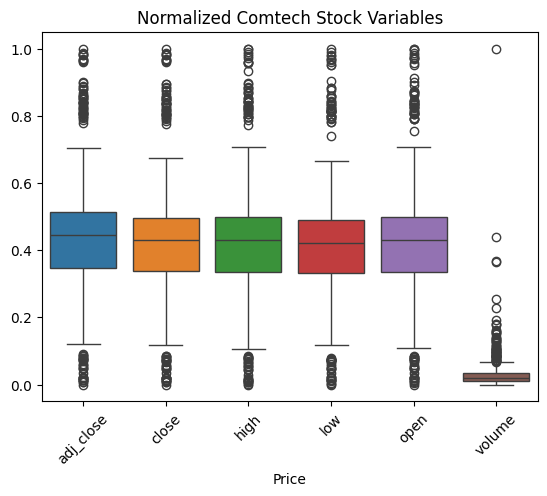

In [25]:
from sklearn.preprocessing import MinMaxScaler

scaler=MinMaxScaler()
normalized_data=scaler.fit_transform(cmtl)

df_normalized_cmtl=pd.DataFrame(normalized_data, columns=cmtl.columns, index=cmtl.index)

sns.boxplot(data= df_normalized_cmtl)
plt.xticks(rotation=45)
plt.title("Normalized Comtech Stock Variables")

plt.show()

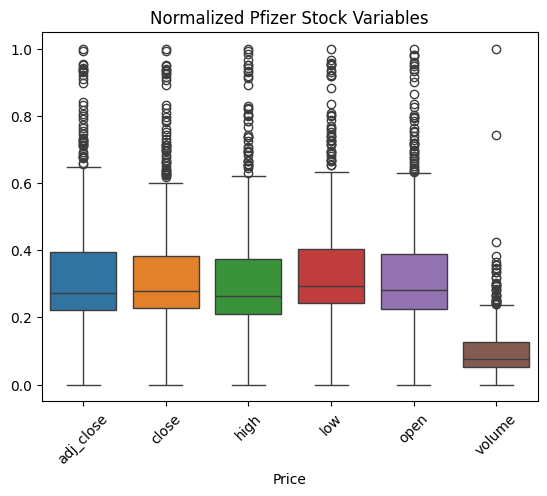

In [26]:
normalized_data=scaler.fit_transform(pfe)

df_normalized_pfe=pd.DataFrame(normalized_data, columns=pfe.columns, index=pfe.index)

sns.boxplot(data= df_normalized_pfe)
plt.xticks(rotation=45)
plt.title("Normalized Pfizer Stock Variables")

plt.show()

Investigate for outliers in Comtech and Pfizer data

In [27]:
from numpy._core.defchararray import lower
percentile_25_cmtl=cmtl.quantile(0.25)
percentile_75_cmtl=cmtl.quantile(0.75)
iqr_cmtl=percentile_75_cmtl-percentile_25_cmtl

upper_limit_cmtl=percentile_75_cmtl + 1.5*iqr_cmtl
lower_limit_cmtl=percentile_25_cmtl - 1.5*iqr_cmtl
print("Lower limit: ", lower_limit_cmtl)
print("Upper limit: ", upper_limit_cmtl)

outlier_mask_cmtl= (cmtl< lower_limit_cmtl) | (cmtl > upper_limit_cmtl)#pandas frame containing booleans
outliers_cmtl= cmtl[outlier_mask_cmtl.any(axis=1)]

print("Number of rows in data containing outliers: ",len(outliers_cmtl))


Lower limit:  Price
adj_close         3.626377
close             3.791251
high              3.801251
low               3.710000
open              3.692500
volume      -119037.500000
dtype: float64
Upper limit:  Price
adj_close        17.938577
close            18.041249
high             18.571249
low              17.670001
open             18.132500
volume       465662.500000
dtype: float64
Number of rows in data containing outliers:  114


In [28]:
percentile_25_pfe=pfe.quantile(0.25)
percentile_75_pfe=pfe.quantile(0.75)
iqr_pfe=percentile_75_pfe-percentile_25_pfe

upper_limit_pfe=percentile_75_pfe + 1.5*iqr_pfe
lower_limit_pfe=percentile_25_pfe - 1.5*iqr_pfe
print("Lower limit: ", lower_limit_pfe)
print("Upper limit: ", upper_limit_pfe)

outlier_mask_pfe= (pfe< lower_limit_pfe) | (pfe > upper_limit_pfe)#pandas frame containing booleans
outliers_pfe= pfe[outlier_mask_pfe.any(axis=1)]

print("Number of rows in data containing outliers: ",len(outliers_pfe))

Lower limit:  Price
adj_close    1.857781e+01
close        2.680061e+01
high         2.675591e+01
low          2.643500e+01
open         2.673433e+01
volume      -2.643300e+06
dtype: float64
Upper limit:  Price
adj_close    3.766762e+01
close        4.815964e+01
high         4.901845e+01
low          4.799500e+01
open         4.829540e+01
volume       6.313990e+07
dtype: float64
Number of rows in data containing outliers:  70


In [29]:
print("Volume outliers: ", outlier_mask_cmtl["volume"].sum())
print("Close price outliers: ", outlier_mask_cmtl["close"].sum())
print(outlier_mask_cmtl.sum())
volume_outliers_cmtl=cmtl[outlier_mask_cmtl["volume"]]
display(volume_outliers_cmtl)


Volume outliers:  63
Close price outliers:  77
Price
adj_close    77
close        77
high         76
low          77
open         76
volume       63
dtype: int64


Price,adj_close,close,high,low,open,volume
Date,,,,,,
2022-03-11,15.286469,15.83,17.73,15.01,17.379999,655700
2022-07-15,8.974006,9.23,9.78,8.97,9.480000,770300
2022-07-28,11.223825,11.42,11.44,11.06,11.150000,709100
2022-12-09,13.270816,13.37,14.05,13.35,14.000000,562400
2022-12-13,12.973042,13.07,14.14,12.88,13.980000,466100
...,...,...,...,...,...,...
2024-04-24,1.750000,1.75,1.78,1.58,1.580000,1186100
2024-04-25,1.870000,1.87,1.90,1.66,1.700000,718500
2024-04-26,2.050000,2.05,2.06,1.83,1.840000,670200


In [30]:
print("Volume outliers: ", outlier_mask_pfe["volume"].sum())
print("Close price outliers: ", outlier_mask_pfe["close"].sum())
print(outlier_mask_pfe.sum())
volume_outliers_pfe=pfe[outlier_mask_pfe["volume"]]
display(volume_outliers_pfe)

Volume outliers:  34
Close price outliers:  47
Price
adj_close    39
close        47
high         42
low          41
open         43
volume       34
dtype: int64


Price,adj_close,close,high,low,open,volume
Date,,,,,,
2020-01-28,25.904133,36.185959,37.466793,36.005692,37.305504,70202408
2020-02-28,22.930241,31.707781,32.201138,30.863379,31.774195,66057447
2020-03-11,22.072586,30.521822,32.144215,30.037951,32.030361,65350213
2020-06-01,24.572403,33.643265,33.899429,33.121441,33.681213,76884979
2020-06-11,23.075603,31.593927,33.851994,31.574953,33.776093,63166642
2020-07-01,23.380512,32.011387,32.770397,31.992411,32.770397,73503009
2020-07-22,26.720572,36.584438,36.745731,35.597721,36.271347,90705554
2020-11-09,27.711655,37.191650,39.838711,36.413662,39.715370,230153864
2020-11-10,27.344057,36.698292,38.462997,36.489563,38.377609,80091668


In [31]:
display(cmtl.loc["2024-03-01": "2024-03-20", ["close", "volume"]])

Price,close,volume
Date,,
2024-03-01,6.60,139300
2024-03-04,6.49,205000
2024-03-05,6.30,141300
2024-03-06,6.15,129400
2024-03-07,6.07,185000
2024-03-08,5.79,283600
2024-03-11,5.73,256800
2024-03-12,5.76,302900
2024-03-13,4.19,2404700


In [32]:
display(pfe.loc["2021-10-25": "2021-11-12", ["close", "volume"]])

Price,close,volume
Date,,
2021-10-25,43.150002,22846200
2021-10-26,43.560001,29729100
2021-10-27,42.970001,22317500
2021-10-28,43.180000,18023400
2021-10-29,43.740002,30307500
2021-11-01,43.639999,32681500
2021-11-02,45.450001,69248000
2021-11-03,44.820000,44593100
2021-11-04,43.849998,38172500


In [33]:
print("Comtech duplicate dates: ", cmtl.index.duplicated().sum())
print("Pfizer duplicate dates: ", pfe.index.duplicated().sum())

print("Comtech negative volumes: ", (cmtl["volume"]<0).sum())
print("Pfizer negative volumes: ", (pfe["volume"]<0).sum())

Comtech duplicate dates:  0
Pfizer duplicate dates:  0
Comtech negative volumes:  0
Pfizer negative volumes:  0


Verify the Comtech and Pfizer data follow expected format


*   date format
*   closing prices are nonnegative


*   low price <= high pirce
*   no dates are not in decreasing order


*   No missing values









In [34]:
for name, df in [("Comtech", cmtl), ("Pfizer", pfe)]:
  print(f"\n{name} Validation")
  print("Date index type: ", type(df.index))#check date format
  print("Nonpositive closing prices: ", (df["close"] <=0).sum()) #check closing prices are nonegative
  print("High below low: ", (df["high"] < df["low"]).sum()) # check hihest recorded price for trading day is not lower than lowest price
  print("Dates sorted: ", df.index.is_monotonic_increasing)#check chronological ordering
  print("Missing values: ", df.isna().sum().sum())#check missing values across every column
  #first .sum() is for single column second is for all columns


Comtech Validation
Date index type:  <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Nonpositive closing prices:  0
High below low:  0
Dates sorted:  True
Missing values:  0

Pfizer Validation
Date index type:  <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Nonpositive closing prices:  0
High below low:  0
Dates sorted:  True
Missing values:  0


For both Comtech and Pfizer

Create boxplots and histograms

Histograms to discern trading volume distribution

Scatterplot of Daily Return vs Trading Volume to display their correlation

Heatmap to display correlation between trading volume, daily return, and closing price

Line plot tracking how trading volume changes overtime

Seasonal Decomposition  to seperate trading volume into estimated trend, seasonal, and residual components to track 5-day trading week patterns

Calculate centered and trailing moving averages to smooth short term fluctuations and identify broader changes in trading activity

STL Decompositon both robust and non robust methods are compared to examine how extreme trading-volume observations influence estimated trends and seasonal patterns

Autocorrelation Analysis both Autocorrelation function and Partial Autocorrelation function are used to investigate relationships between trading volumes across different trading-day lags


Time-Series Visualization: Line plots are used to identify changes in trading volume over time, including periods of elevated trading activity and unusually large spikes.

Seasonal Decomposition: Additive and multiplicative decomposition methods are applied to separate trading volume into estimated trend, seasonal, and residual components. A five-observation period is used to explore potential trading-week patterns.

Moving Averages: Centered and trailing moving averages are calculated to smooth short-term fluctuations and identify broader changes in trading activity.

STL Decomposition: Robust and non-robust STL methods are compared to examine how extreme trading-volume observations influence estimated trends and seasonal patterns.

Autocorrelation Analysis: The Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) are used to investigate relationships between trading volumes across different trading-day lags.

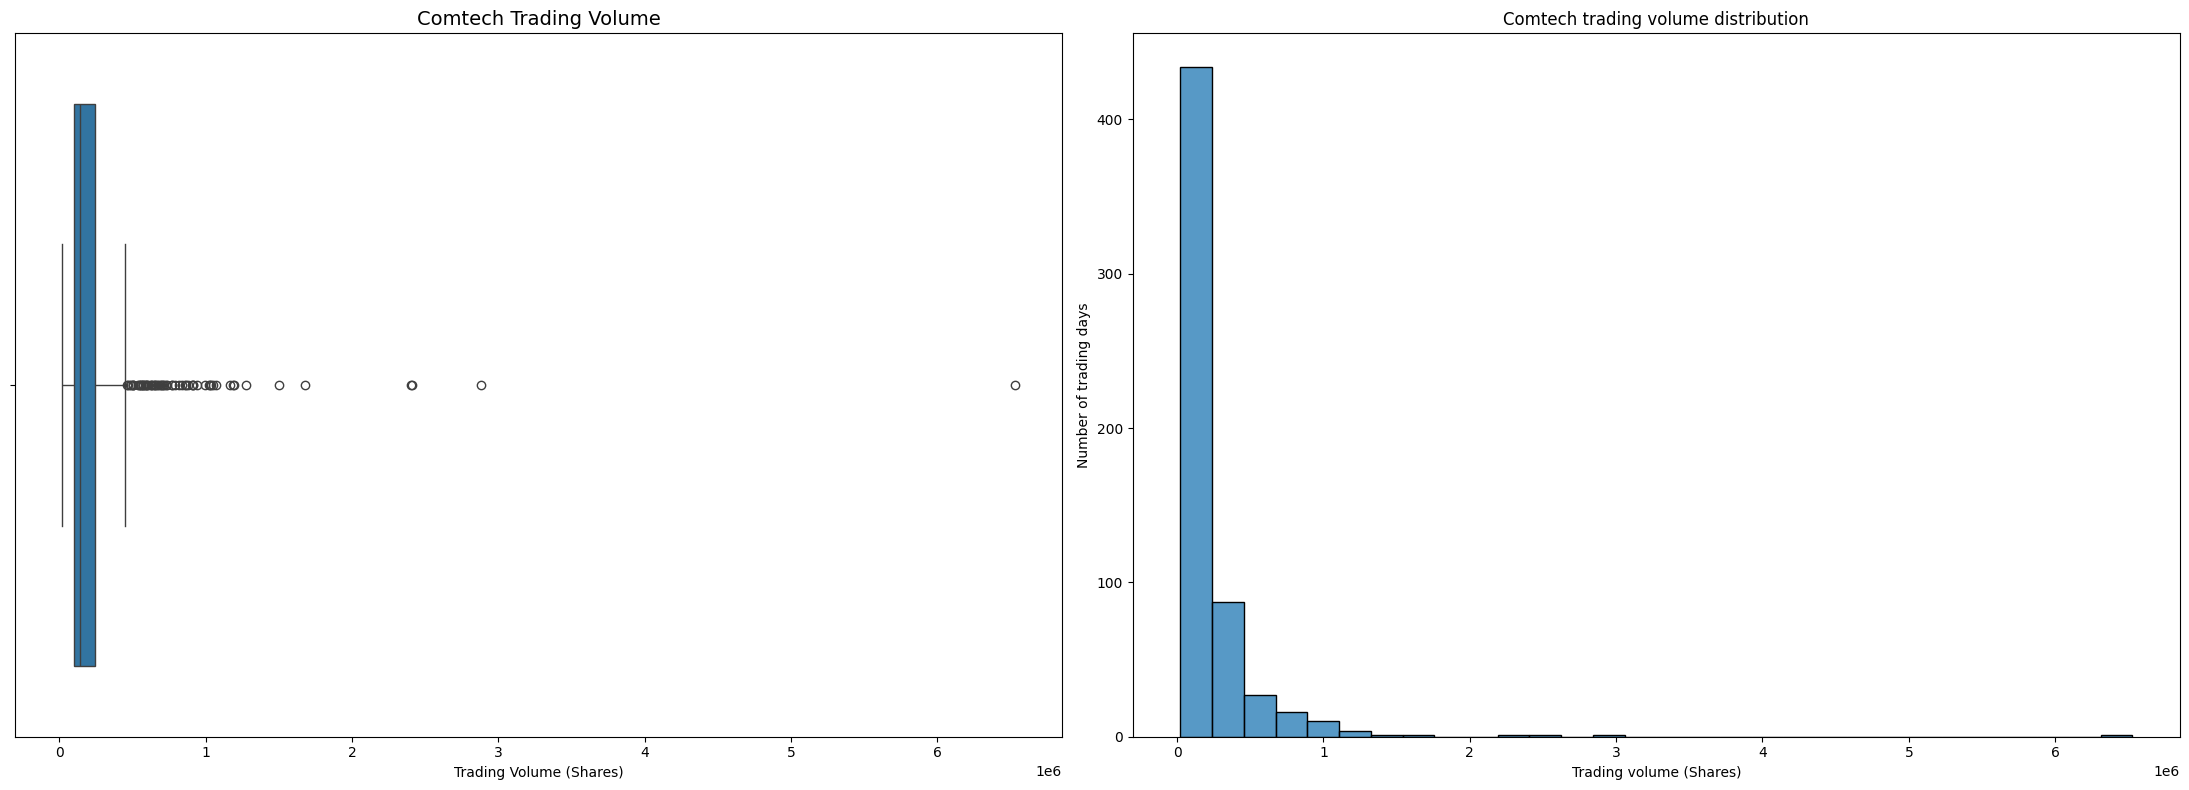

In [35]:
#set figure and axes
fig, ax = plt.subplots(1,2,figsize=(22,8))

#create boxplot
sns.boxplot(
    data=cmtl,
    x='volume',
    orient="h",
    ax=ax[0]
)


ax[0].set_title('Comtech Trading Volume', fontsize='14')
ax[0].set_xlabel("Trading Volume (Shares)")

#plot histogram showing distribution
sns.histplot(
    data=cmtl,
    x="volume",
    bins=30,
    ax=ax[1]
)

ax[1].set_title('Comtech trading volume distribution')
ax[1].set_xlabel("Trading volume (Shares)")
ax[1].set_ylabel("Number of trading days")
plt.tight_layout()

#display plots
plt.show()

Histograms of the distribution trading volume

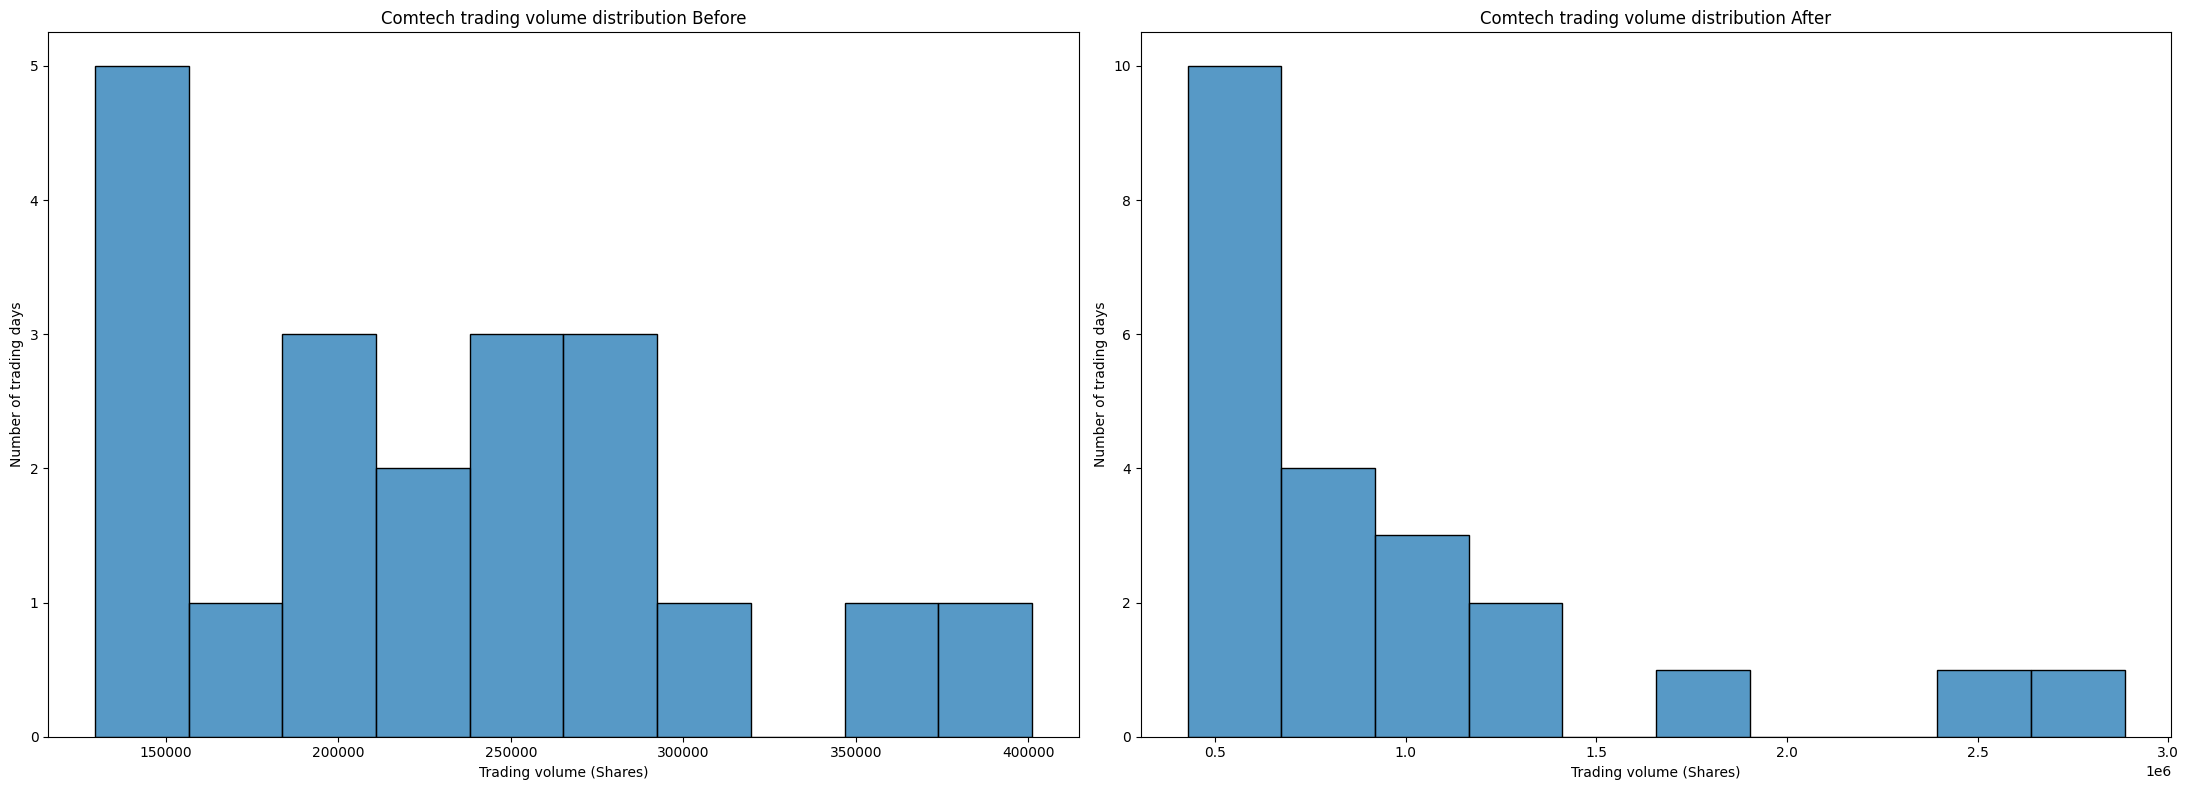

In [36]:
fig, ax = plt.subplots(1,2,figsize=(22,8))

df_filter1_cmtl= cmtl.loc["2024-02-13" : "2024-03-12"]
df_filter2_cmtl=cmtl.loc["2024-03-13":"2024-04-12"]
sns.histplot(
    data=df_filter1_cmtl,
    x="volume",
    bins=10,
    ax=ax[0]
)

ax[0].set_title('Comtech trading volume distribution Before')
ax[0].set_xlabel("Trading volume (Shares)")
ax[0].set_ylabel("Number of trading days")


sns.histplot(
    data=df_filter2_cmtl,
    x="volume",
    bins=10,
    ax=ax[1]
)

ax[1].set_title('Comtech trading volume distribution After')
ax[1].set_xlabel("Trading volume (Shares)")
ax[1].set_ylabel("Number of trading days")

plt.tight_layout()
plt.show()

In [37]:
cmtl["daily_return"]=cmtl["close"].pct_change()*100
pfe["daily_return"]=pfe["close"].pct_change()*100

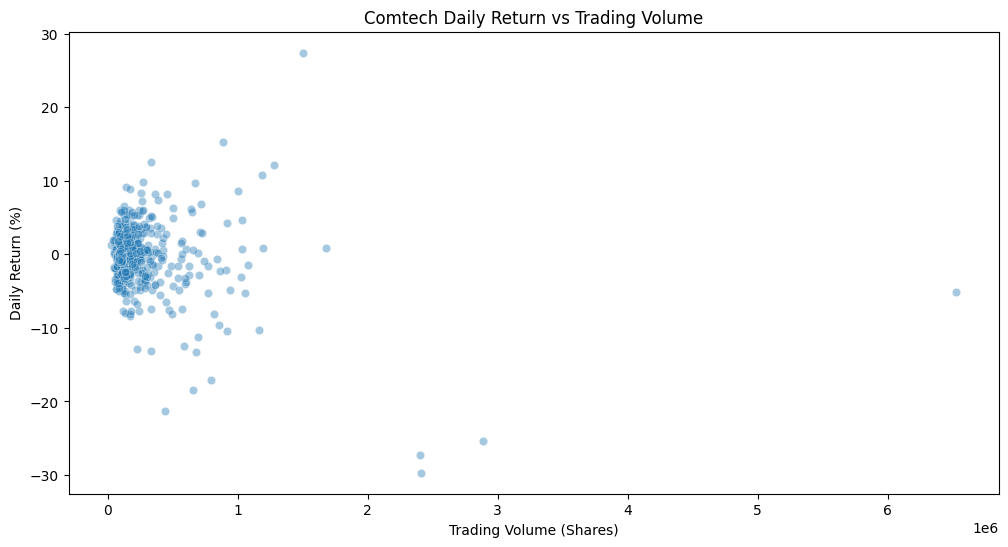

In [38]:
plt.figure(figsize=(12,6))
sns.scatterplot(
    data=cmtl,
    x="volume",
    y="daily_return",
    alpha=0.4,
)
plt.title("Comtech Daily Return vs Trading Volume")
plt.xlabel("Trading Volume (Shares)")
plt.ylabel("Daily Return (%)")
plt.show()

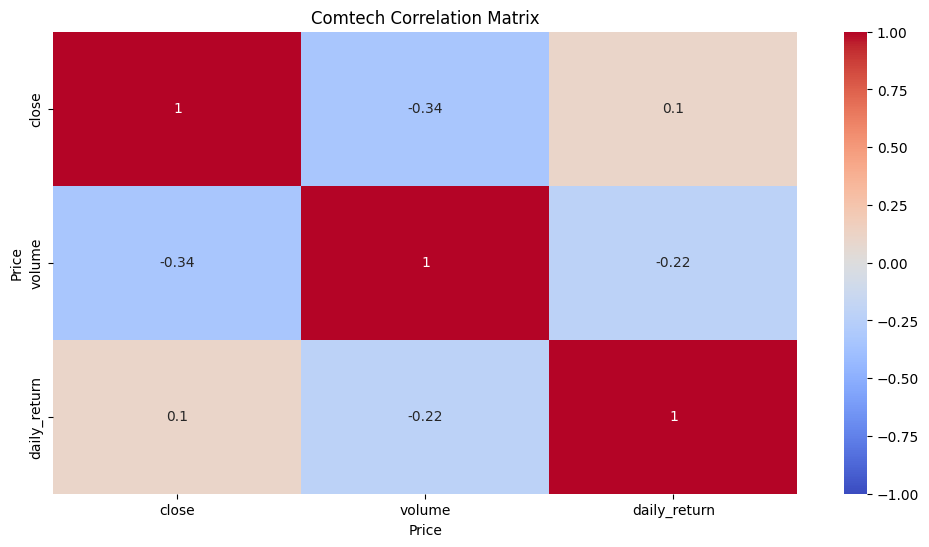

In [39]:
plt.figure(figsize=(12,6))

corr_matrix=cmtl[["close", "volume", "daily_return"]].corr()
pfe_heatmap=sns.heatmap(
    data=corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Comtech Correlation Matrix")
plt.show()

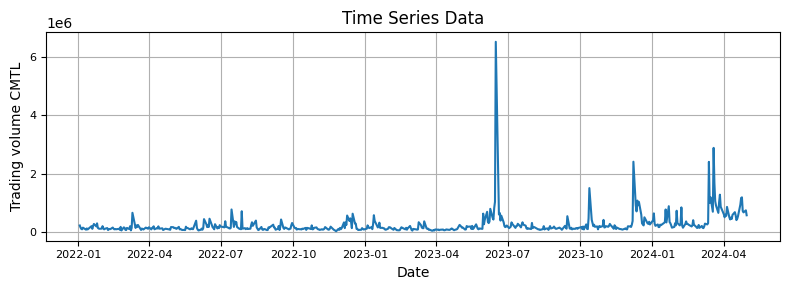

In [40]:
plt.figure(figsize=(8,3))
plt.plot(cmtl.index,cmtl["volume"])
plt.xlabel('Date', fontsize=10)
plt.ylabel('Trading volume CMTL', fontsize=10)
plt.title('Time Series Data', fontsize=12)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()

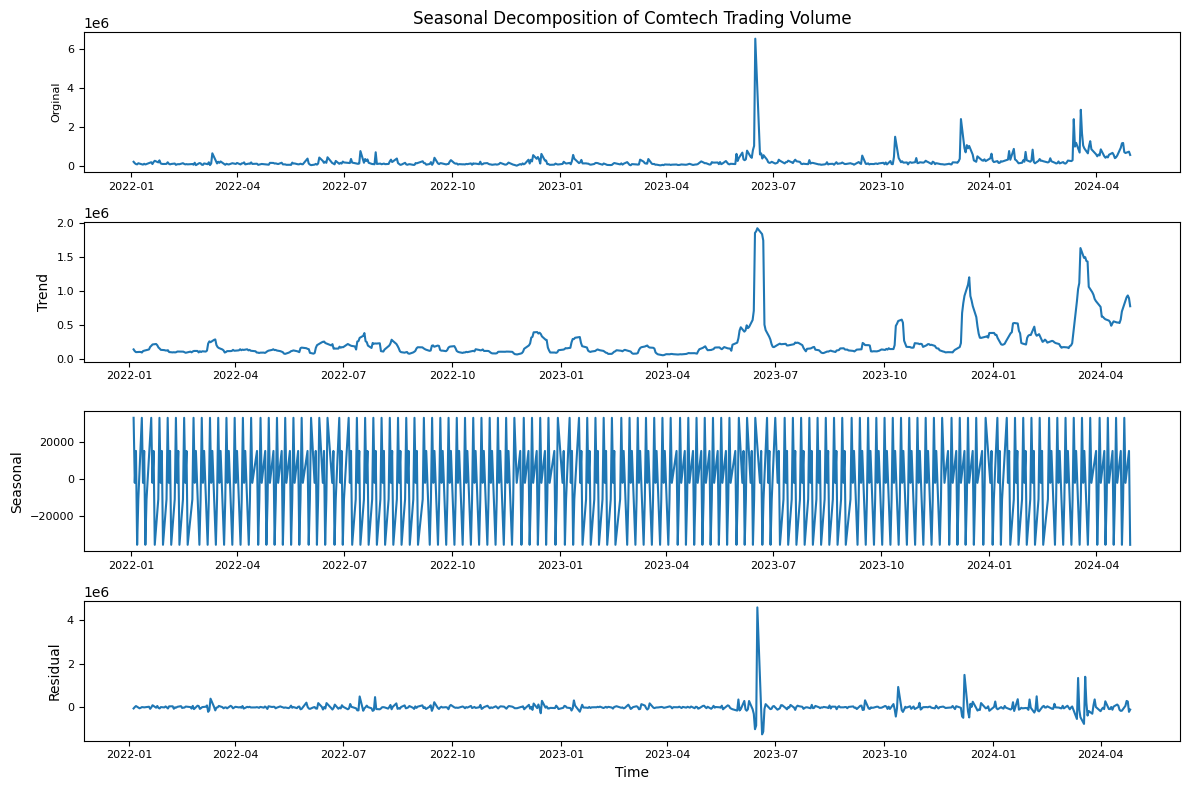

In [41]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt
result_cmtl=seasonal_decompose(cmtl["volume"], model="additive", period=5)
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4,1, figsize=(12,8))

ax1.plot(cmtl["volume"])
ax1.set_ylabel('Orginal', fontsize=8)
ax1.set_title('Seasonal Decomposition of Comtech Trading Volume', fontsize=12)

ax2.plot(result_cmtl.trend)
ax2.set_ylabel('Trend', fontsize=10)

ax3.plot(result_cmtl.seasonal)
ax3.set_ylabel('Seasonal', fontsize=10)

ax4.plot(result_cmtl.resid)
ax4.set_xlabel('Time', fontsize=10)
ax4.set_ylabel('Residual', fontsize=10)

for ax in [ax1, ax2, ax3, ax4]:
  ax.tick_params(axis='both', labelsize=8)

plt.tight_layout()
plt.show()

0


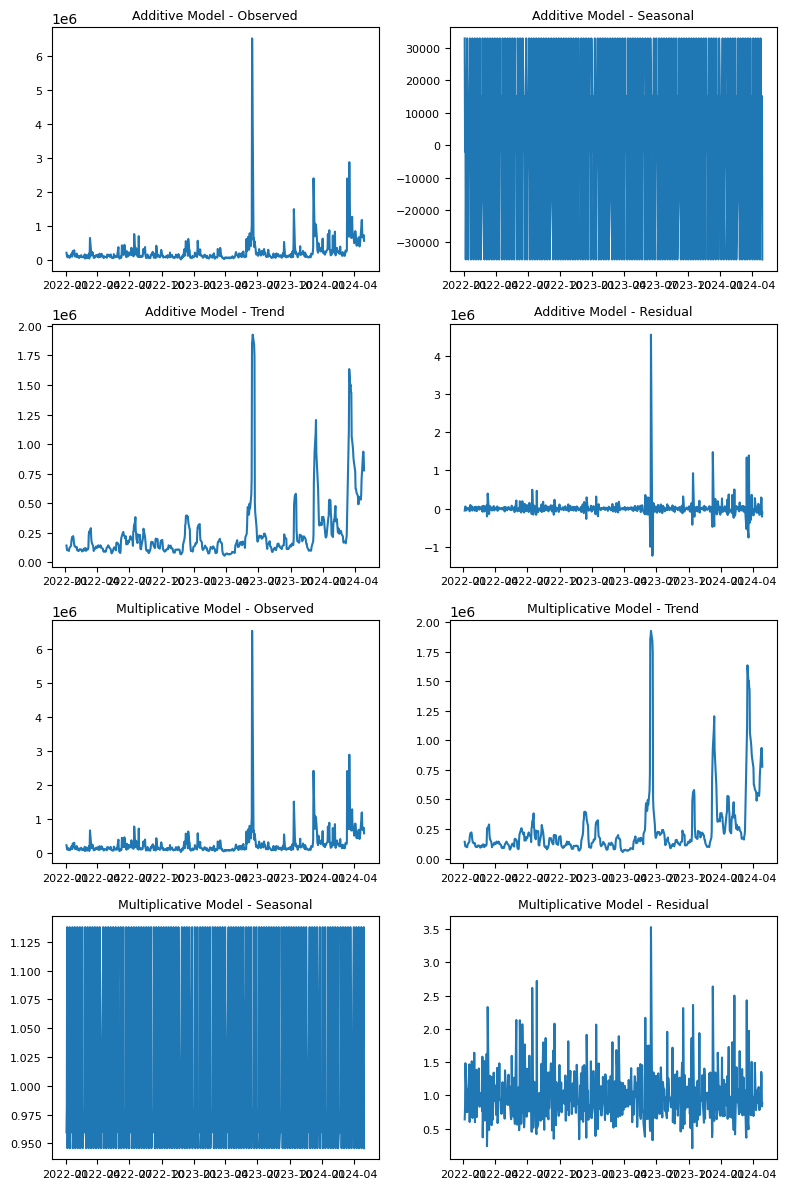

In [42]:
result_add_cmtl=seasonal_decompose(cmtl["volume"], model='additive', period=5)
print((cmtl["volume"]<=0).sum())
result_mul_cmtl=seasonal_decompose(cmtl["volume"], model='multiplicative', period=5)

fig,axes=plt.subplots(4,2,figsize=(8,12))

axes[0,0].plot(result_add_cmtl.observed)
axes[0,0].set_title('Additive Model - Observed', fontsize=9)

axes[1,0].plot(result_add_cmtl.trend)
axes[1,0].set_title('Additive Model - Trend', fontsize=9)

axes[0,1].plot(result_add_cmtl.seasonal)
axes[0,1].set_title('Additive Model - Seasonal', fontsize=9)

axes[1,1].plot(result_add_cmtl.resid)
axes[1,1].set_title('Additive Model - Residual', fontsize=9)

axes[2,0].plot(result_mul_cmtl.observed)
axes[2,0].set_title('Multiplicative Model - Observed', fontsize=9)

axes[2,1].plot(result_mul_cmtl.trend)
axes[2,1].set_title('Multiplicative Model - Trend', fontsize=9)

axes[3,0].plot(result_mul_cmtl.seasonal)
axes[3,0].set_title('Multiplicative Model - Seasonal', fontsize=9)

axes[3,1].plot(result_mul_cmtl.resid)
axes[3,1].set_title('Multiplicative Model - Residual', fontsize=9)

for ax in axes.flatten():
  ax.tick_params(axis='both', labelsize=8)

plt.tight_layout()
plt.show()

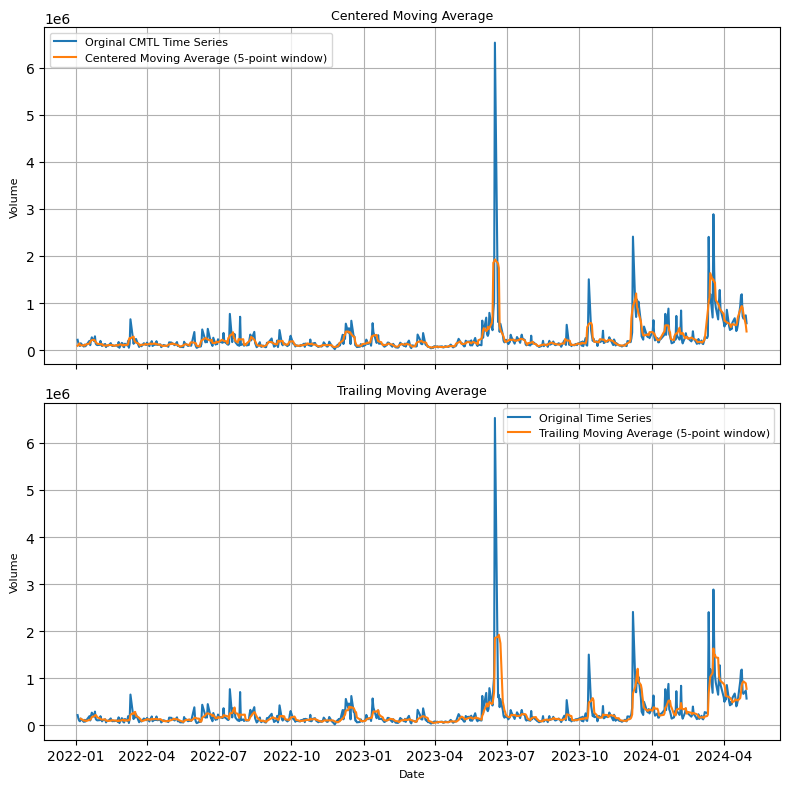

In [43]:
centered_window_size=5
trailing_window_size=5
centered_ma_cmtl=np.convolve(cmtl["volume"], np.ones(centered_window_size)/centered_window_size, mode='same')
trailing_ma_cmtl=np.convolve(cmtl["volume"], np.ones(trailing_window_size)/trailing_window_size, mode='valid')
residual= cmtl['volume']-centered_ma_cmtl

fig, (ax1, ax2) = plt.subplots(2,1,figsize=(8,8), sharex=True)

ax1.plot(cmtl.index, cmtl["volume"], label="Orginal CMTL Time Series")
ax1.plot(cmtl.index, centered_ma_cmtl, label=f"Centered Moving Average ({centered_window_size}-point window)" )
ax1.set_title("Centered Moving Average", fontsize=9)
ax1.set_ylabel("Volume", fontsize=8)
ax1.legend(fontsize=8)
ax1.grid(True)

ax2.plot(cmtl.index, cmtl["volume"], label="Original Time Series")
ax2.plot(cmtl.index[trailing_window_size-1:], trailing_ma_cmtl, label=f"Trailing Moving Average ({trailing_window_size}-point window)")
ax2.set_title("Trailing Moving Average", fontsize=9)
ax2.set_ylabel("Volume", fontsize=8)
ax2.set_xlabel("Date", fontsize=8)
ax2.legend(fontsize=8)
ax2.grid(True)

plt.tight_layout()
plt.show()

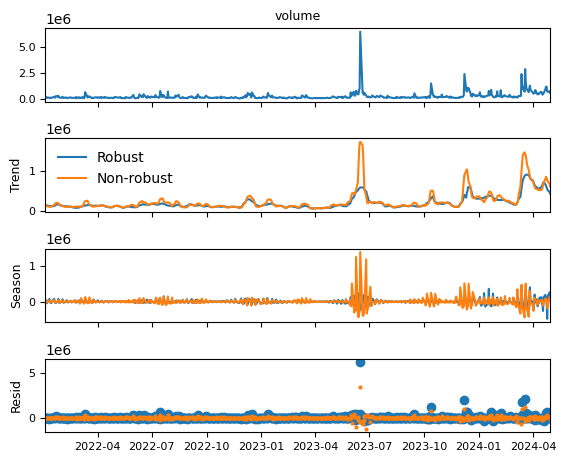

In [44]:
from statsmodels.tsa.seasonal import STL

def add_stl_plot(fig, res, legend):
  axs=fig.get_axes()
  comps=["trend", "seasonal", "resid"]
  for ax, comp in zip(axs[1:], comps):
    series=getattr(res,comp)
    if comp == "resid":
      ax.plot(series, marker="o", linestyle="none", markersize=2)
    else:
      ax.plot(series)
      if comp=="trend":
        ax.legend(legend, frameon=False)
stl=STL(cmtl["volume"], period=5, robust=True)
res_robust=stl.fit()
fig=res_robust.plot()

for ax in fig.get_axes():
  ax.set_title(ax.get_title(), fontsize=9)
  ax.set_xlabel(ax.get_xlabel(), fontsize=9)
  ax.set_ylabel(ax.get_ylabel(), fontsize=9)
  ax.tick_params(axis='both', labelsize=8)

res_non_robust=STL(cmtl["volume"], period=5, robust=False).fit()
add_stl_plot(fig, res_non_robust, ["Robust", "Non-robust"])

plt.show()

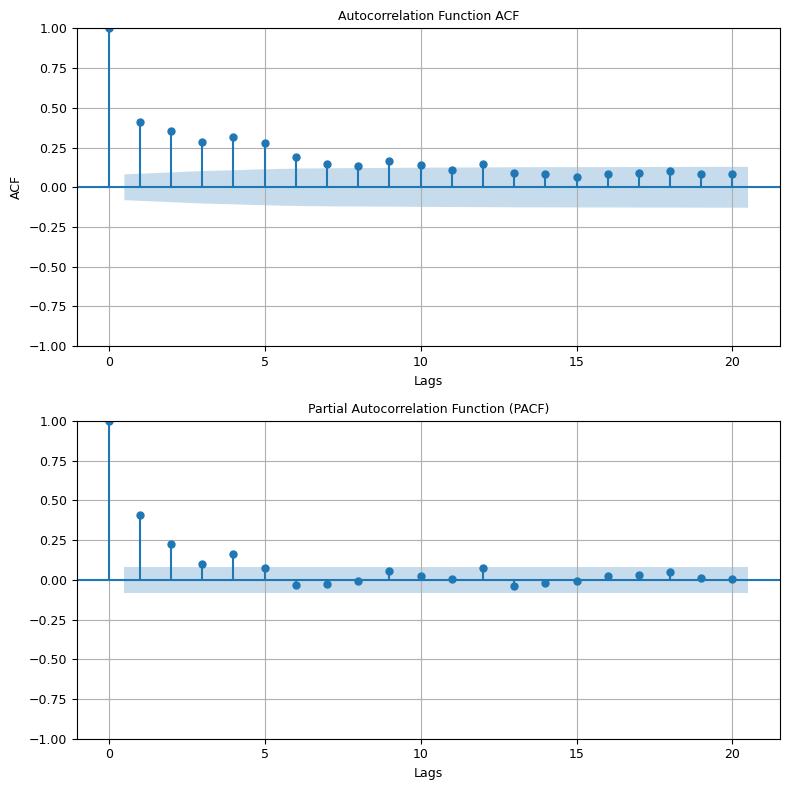

In [45]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, (ax1, ax2)=plt.subplots(2,1,figsize=(8,8))
plot_acf(cmtl["volume"], lags=20, ax=ax1)
ax1.set_title("Autocorrelation Function ACF", fontsize=9)
ax1.set_xlabel('Lags', fontsize=9)
ax1.set_ylabel('ACF', fontsize=9)
ax1.grid(True)

plot_pacf(cmtl["volume"], lags=20, ax=ax2)
ax2.set_title('Partial Autocorrelation Function (PACF)', fontsize=9)
ax2.set_xlabel('Lags', fontsize=9)
ax2.grid(True)

for ax in [ax1,ax2]:
  ax.tick_params(axis='both', labelsize=9)

plt.tight_layout()
plt.show()

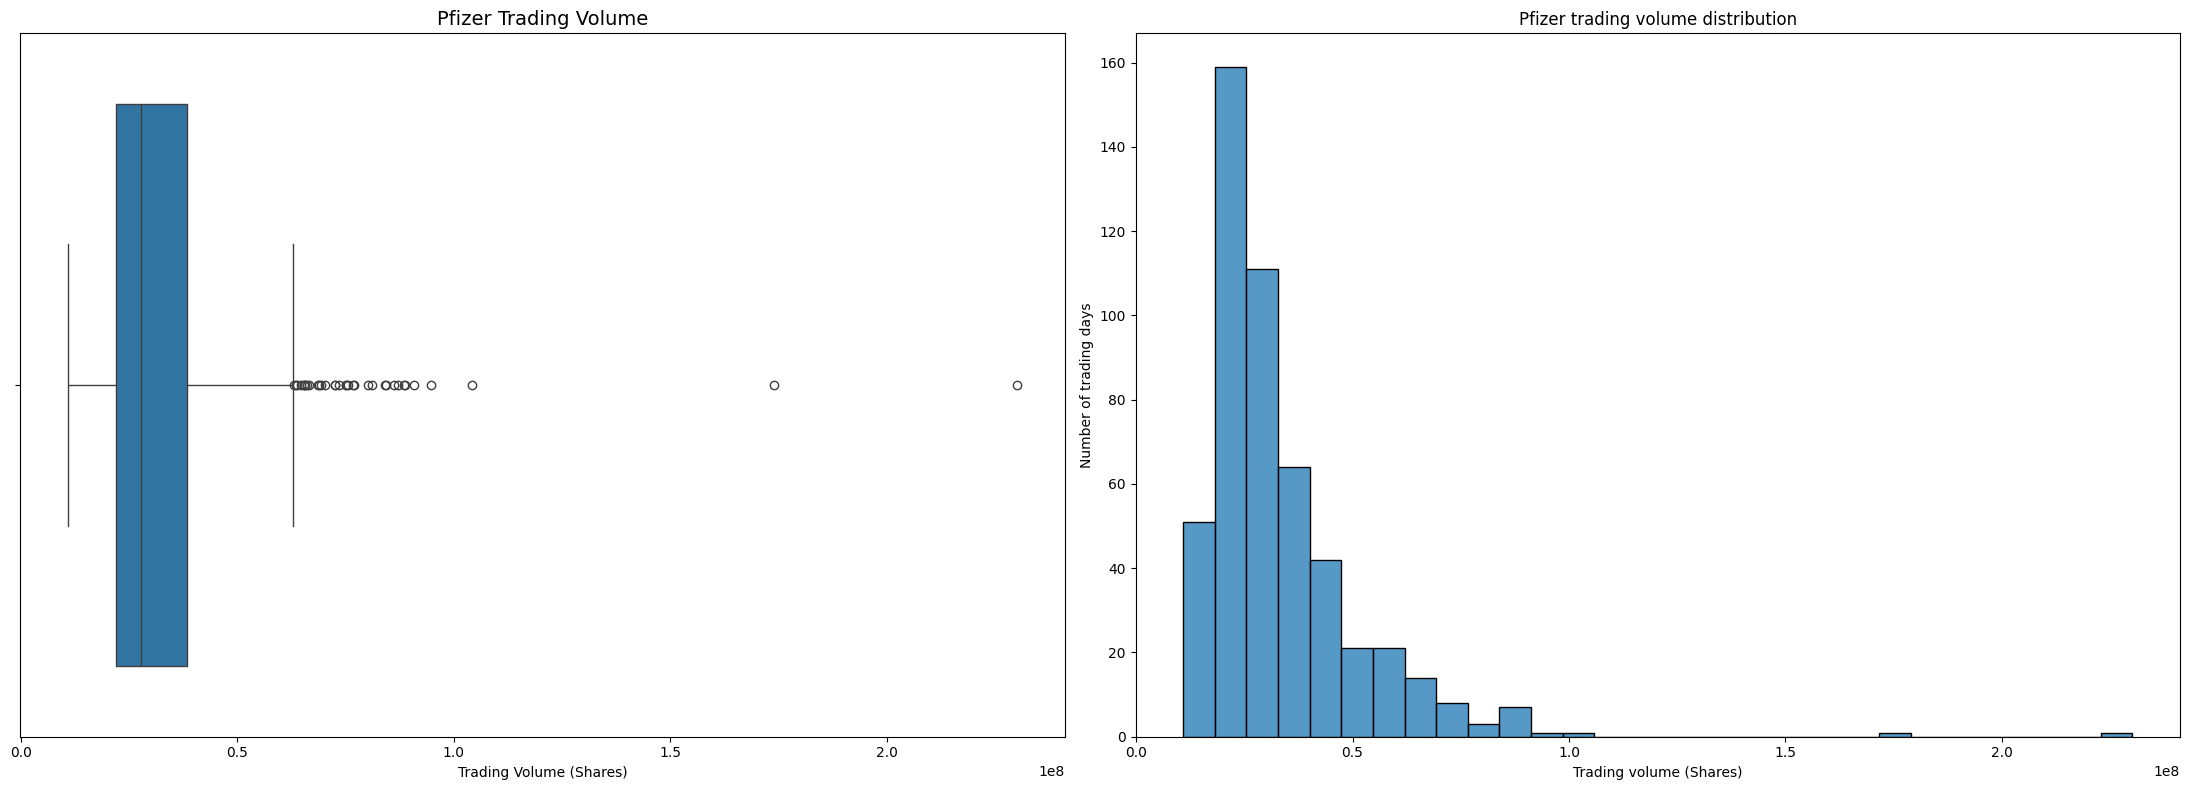

In [46]:
fig, ax = plt.subplots(1,2,figsize=(22,8))
sns.boxplot(
    data=pfe,
    x='volume',
    orient="h",
    ax=ax[0]
)

ax[0].set_title('Pfizer Trading Volume', fontsize='14')
ax[0].set_xlabel("Trading Volume (Shares)")

sns.histplot(
    data=pfe,
    x="volume",
    bins=30,
    ax=ax[1]
)

ax[1].set_title('Pfizer trading volume distribution')
ax[1].set_xlabel("Trading volume (Shares)")
ax[1].set_ylabel("Number of trading days")
plt.tight_layout()
plt.show()

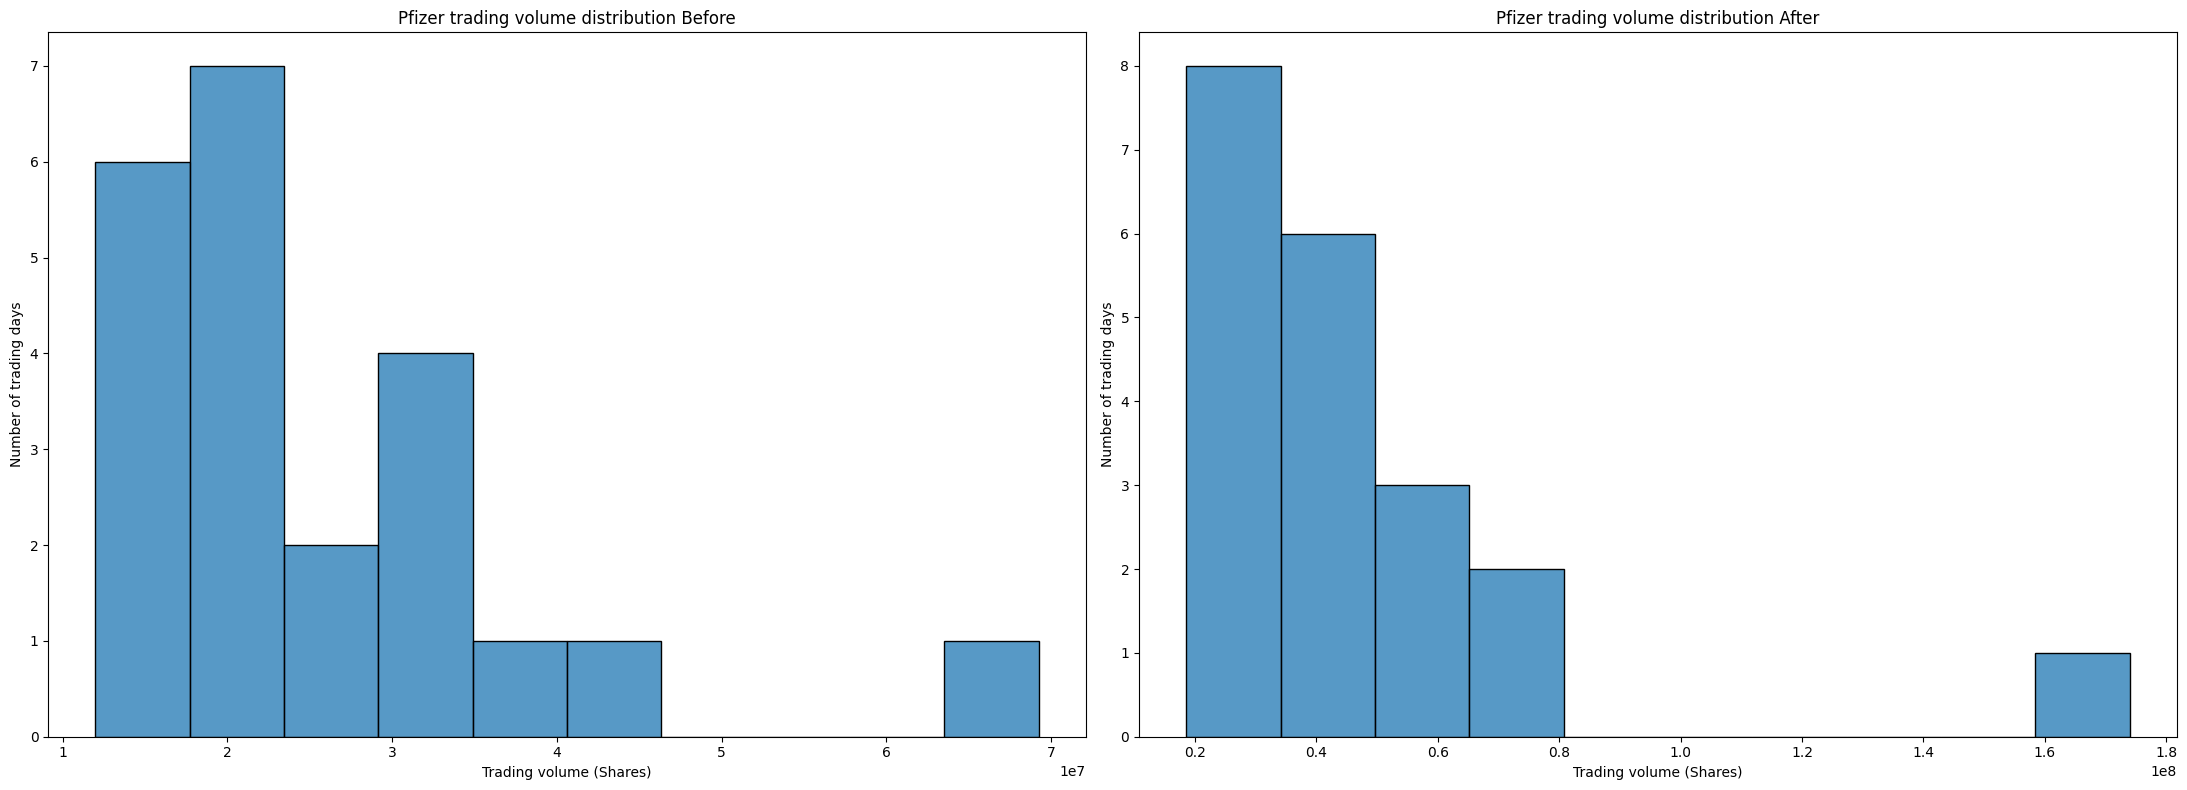

In [47]:
fig, ax = plt.subplots(1,2,figsize=(22,8))

df_filter1_pfe= pfe.loc["2021-10-06" : "2021-11-04"]
df_filter2_pfe=pfe.loc["2021-11-05":"2021-12-03"]
sns.histplot(
    data=df_filter1_pfe,
    x="volume",
    bins=10,
    ax=ax[0]
)

ax[0].set_title('Pfizer trading volume distribution Before')
ax[0].set_xlabel("Trading volume (Shares)")
ax[0].set_ylabel("Number of trading days")


sns.histplot(
    data=df_filter2_pfe,
    x="volume",
    bins=10,
    ax=ax[1]
)

ax[1].set_title('Pfizer trading volume distribution After')
ax[1].set_xlabel("Trading volume (Shares)")
ax[1].set_ylabel("Number of trading days")

plt.tight_layout()
plt.show()

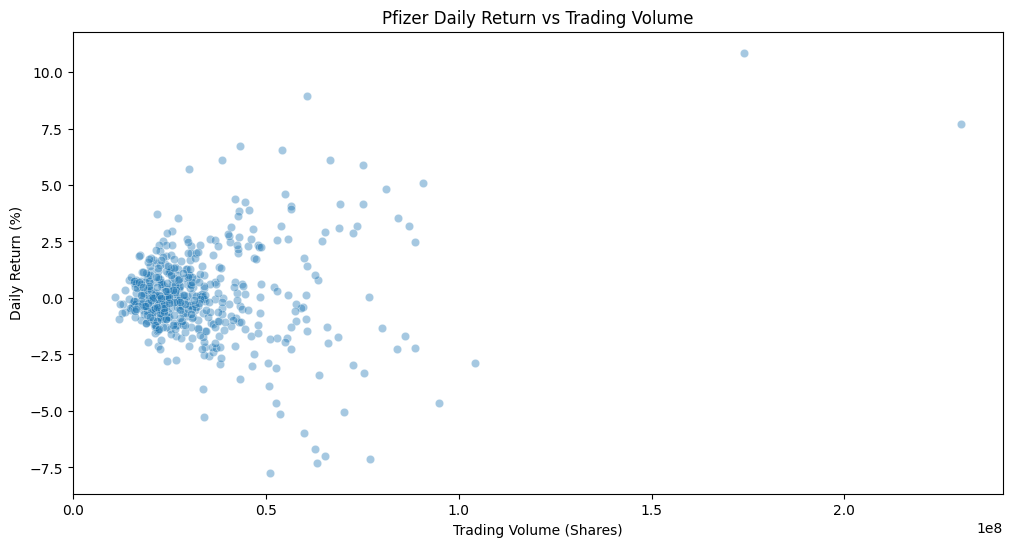

In [48]:
plt.figure(figsize=(12,6))
sns.scatterplot(
    data=pfe,
    x="volume",
    y="daily_return",
    alpha=0.4,
)
plt.title("Pfizer Daily Return vs Trading Volume")
plt.xlabel("Trading Volume (Shares)")
plt.ylabel("Daily Return (%)")
plt.show()

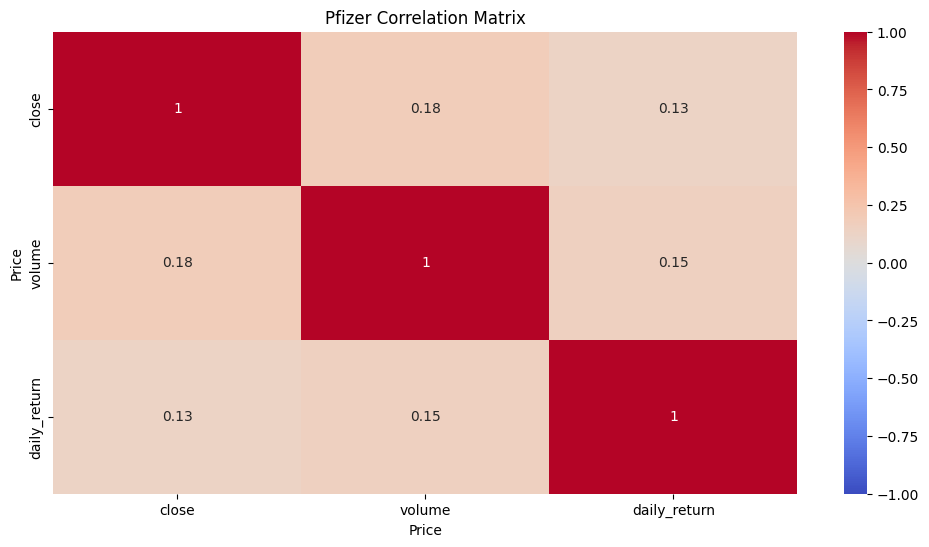

In [49]:
plt.figure(figsize=(12,6))

corr_matrix=pfe[["close", "volume", "daily_return"]].corr()
pfe_heatmap=sns.heatmap(
    data=corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Pfizer Correlation Matrix")
plt.show()

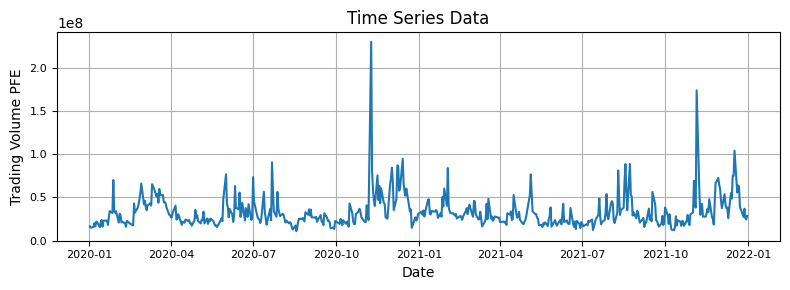

In [50]:
plt.figure(figsize=(8,3))
plt.plot(pfe.index,pfe["volume"])
plt.xlabel('Date', fontsize=10)
plt.ylabel('Trading Volume PFE', fontsize=10)
plt.title('Time Series Data', fontsize=12)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()

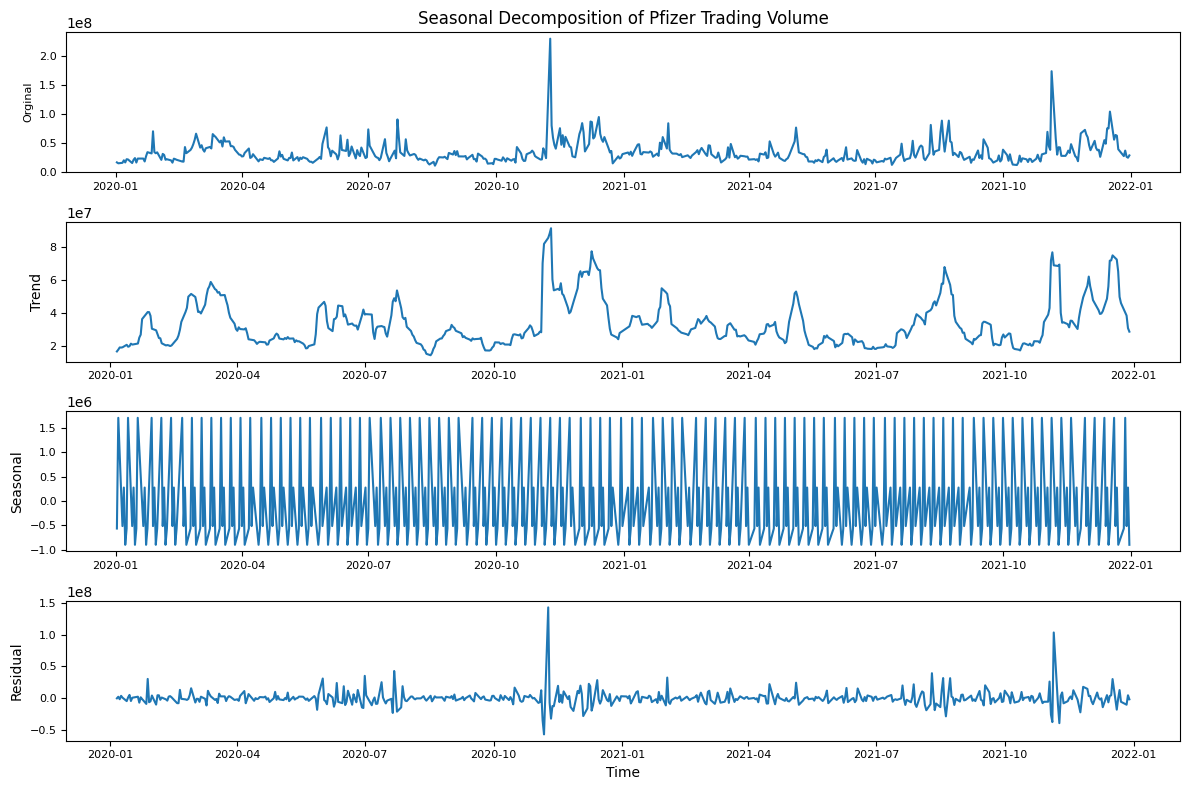

In [51]:
result_pfe=seasonal_decompose(pfe["volume"], model="additive", period=5)
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4,1, figsize=(12,8))

ax1.plot(pfe["volume"])
ax1.set_ylabel('Orginal', fontsize=8)
ax1.set_title('Seasonal Decomposition of Pfizer Trading Volume', fontsize=12)

ax2.plot(result_pfe.trend)
ax2.set_ylabel('Trend', fontsize=10)

ax3.plot(result_pfe.seasonal)
ax3.set_ylabel('Seasonal', fontsize=10)

ax4.plot(result_pfe.resid)
ax4.set_xlabel('Time', fontsize=10)
ax4.set_ylabel('Residual', fontsize=10)

for ax in [ax1, ax2, ax3, ax4]:
  ax.tick_params(axis='both', labelsize=8)

plt.tight_layout()
plt.show()

0


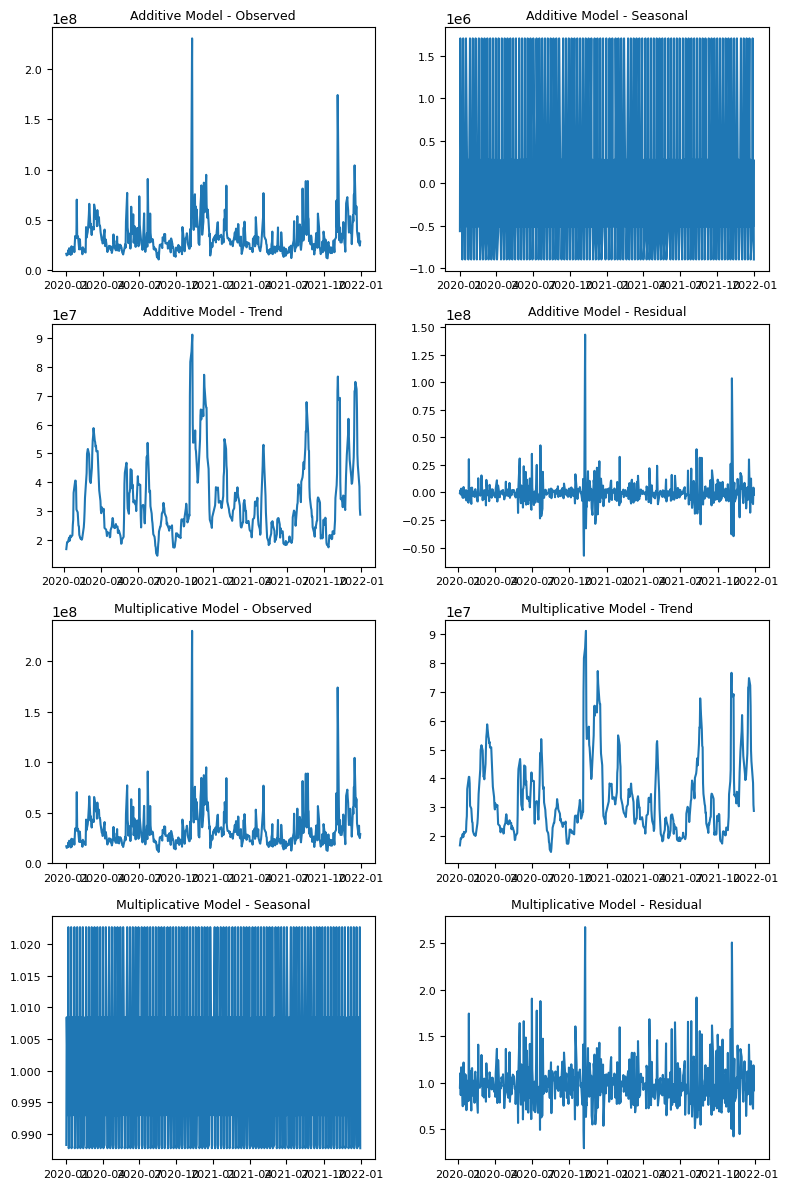

In [52]:
result_add_pfe=seasonal_decompose(pfe["volume"], model='additive', period=5)
print((pfe["volume"]<=0).sum())
result_mul_pfe=seasonal_decompose(pfe["volume"], model='multiplicative', period=5)

fig,axes=plt.subplots(4,2,figsize=(8,12))

axes[0,0].plot(result_add_pfe.observed)
axes[0,0].set_title('Additive Model - Observed', fontsize=9)

axes[1,0].plot(result_add_pfe.trend)
axes[1,0].set_title('Additive Model - Trend', fontsize=9)

axes[0,1].plot(result_add_pfe.seasonal)
axes[0,1].set_title('Additive Model - Seasonal', fontsize=9)

axes[1,1].plot(result_add_pfe.resid)
axes[1,1].set_title('Additive Model - Residual', fontsize=9)

axes[2,0].plot(result_mul_pfe.observed)
axes[2,0].set_title('Multiplicative Model - Observed', fontsize=9)

axes[2,1].plot(result_mul_pfe.trend)
axes[2,1].set_title('Multiplicative Model - Trend', fontsize=9)

axes[3,0].plot(result_mul_pfe.seasonal)
axes[3,0].set_title('Multiplicative Model - Seasonal', fontsize=9)

axes[3,1].plot(result_mul_pfe.resid)
axes[3,1].set_title('Multiplicative Model - Residual', fontsize=9)

for ax in axes.flatten():
  ax.tick_params(axis='both', labelsize=8)

plt.tight_layout()
plt.show()

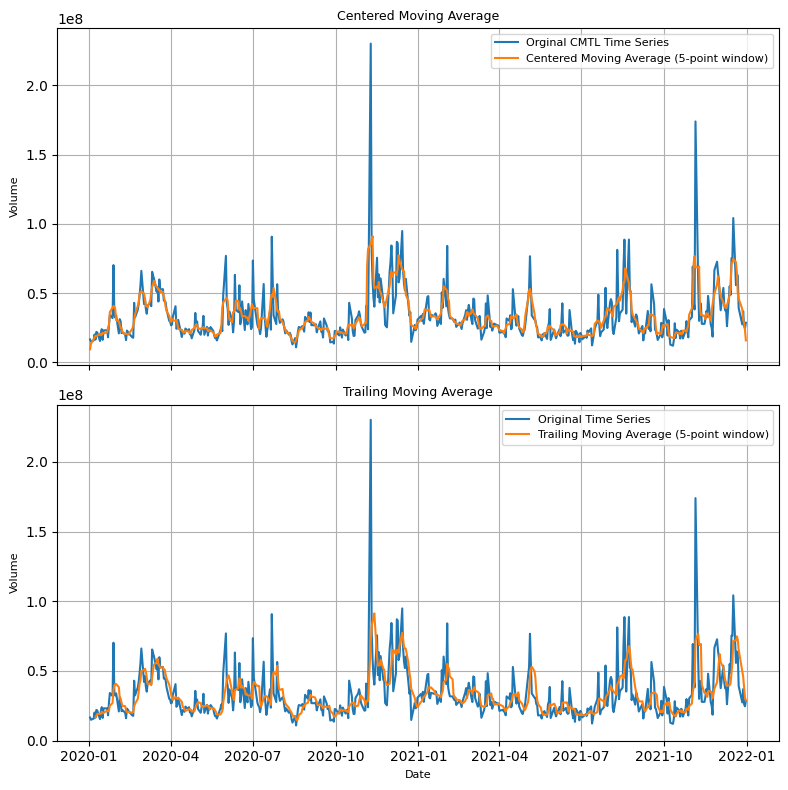

In [53]:
centered_window_size=5
trailing_window_size=5
centered_ma_pfe=np.convolve(pfe["volume"], np.ones(centered_window_size)/centered_window_size, mode='same')
trailing_ma_pfe=np.convolve(pfe["volume"], np.ones(trailing_window_size)/trailing_window_size, mode='valid')
residual= pfe['volume']-centered_ma_pfe

fig, (ax1, ax2) = plt.subplots(2,1,figsize=(8,8), sharex=True)

ax1.plot(pfe.index, pfe["volume"], label="Orginal CMTL Time Series")
ax1.plot(pfe.index, centered_ma_pfe, label=f"Centered Moving Average ({centered_window_size}-point window)" )
ax1.set_title("Centered Moving Average", fontsize=9)
ax1.set_ylabel("Volume", fontsize=8)
ax1.legend(fontsize=8)
ax1.grid(True)

ax2.plot(pfe.index, pfe["volume"], label="Original Time Series")
ax2.plot(pfe.index[trailing_window_size-1:], trailing_ma_pfe, label=f"Trailing Moving Average ({trailing_window_size}-point window)")
ax2.set_title("Trailing Moving Average", fontsize=9)
ax2.set_ylabel("Volume", fontsize=8)
ax2.set_xlabel("Date", fontsize=8)
ax2.legend(fontsize=8)
ax2.grid(True)

plt.tight_layout()
plt.show()

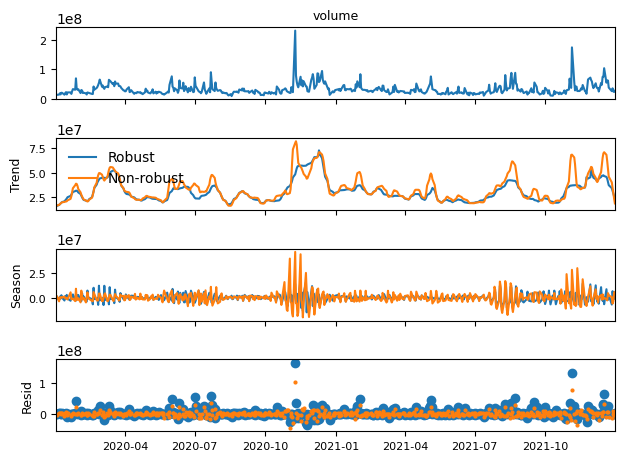

In [54]:
def add_stl_plot(fig, res, legend):
  axs=fig.get_axes()
  comps=["trend", "seasonal", "resid"]
  for ax, comp in zip(axs[1:], comps):
    series=getattr(res,comp)
    if comp == "resid":
      ax.plot(series, marker="o", linestyle="none", markersize=2)
    else:
      ax.plot(series)
      if comp=="trend":
        ax.legend(legend, frameon=False)
stl=STL(pfe["volume"], period=5, robust=True)
res_robust=stl.fit()
fig=res_robust.plot()

for ax in fig.get_axes():
  ax.set_title(ax.get_title(), fontsize=9)
  ax.set_xlabel(ax.get_xlabel(), fontsize=9)
  ax.set_ylabel(ax.get_ylabel(), fontsize=9)
  ax.tick_params(axis='both', labelsize=8)

res_non_robust=STL(pfe["volume"], period=5, robust=False).fit()
add_stl_plot(fig, res_non_robust, ["Robust", "Non-robust"])

plt.show()

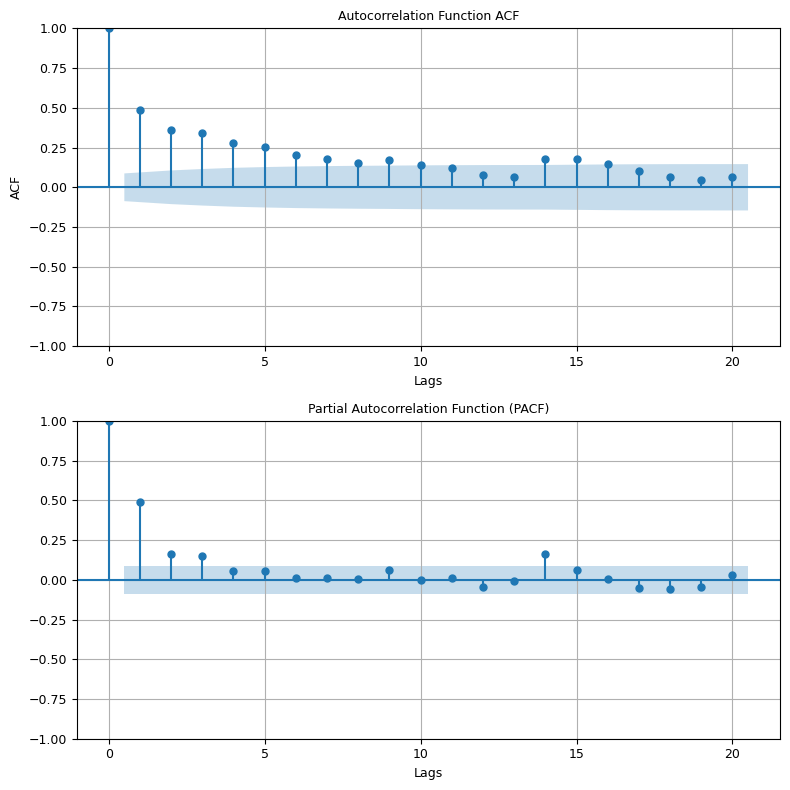

In [55]:
fig, (ax1, ax2)=plt.subplots(2,1,figsize=(8,8))
plot_acf(pfe["volume"], lags=20, ax=ax1)
ax1.set_title("Autocorrelation Function ACF", fontsize=9)
ax1.set_xlabel('Lags', fontsize=9)
ax1.set_ylabel('ACF', fontsize=9)
ax1.grid(True)

plot_pacf(pfe["volume"], lags=20, ax=ax2)
ax2.set_title('Partial Autocorrelation Function (PACF)', fontsize=9)
ax2.set_xlabel('Lags', fontsize=9)
ax2.grid(True)

for ax in [ax1,ax2]:
  ax.tick_params(axis='both', labelsize=9)

plt.tight_layout()
plt.show()

Feature Engineering

calculate rolling average based on 20 consecutive trading observations

amount of trading volume we normally expect for a stock based on recent days


In [56]:
#Feature engineering
#calculate rolling average based on 20 consecutive trading observations
#amount of trading volume we normally expect for a stock based on recent days
cmtl['volume_baseline']=(
    cmtl["volume"].rolling(window=20).mean().shift(1)
)
#calculate ratio between todays volume/historical average volume
cmtl['volume_ratio']=(cmtl["volume"]/cmtl["volume_baseline"])
#calculate today's volume - yesterday's volume
cmtl['volume_diff']=cmtl["volume"].diff()

In [57]:
#Feature engineering
#calculate rolling average based on 20 consecutive trading observations
#amount of trading volume we normally expect for a stock based on recent days
pfe['volume_baseline']=(
    pfe["volume"].rolling(window=20).mean().shift(1)
)
#calculate ratio between todays volume/historical average volume
pfe['volume_ratio']=(pfe["volume"]/pfe["volume_baseline"])
#calculate today's volume - yesterday's volume
pfe['volume_diff']=pfe["volume"].diff()

Use differencing to tranform non-stationary time series into stationary one

ADF test checks whether time series has unit root, which implies it nonstationary

Does trading volume drift away from its previous level

/tmp/ipykernel_3500/2052983366.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_cmtl_res=adfuller(cmtl["volume"])
/tmp/ipykernel_3500/2052983366.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_cmtl=adfuller(cmtl["volume_diff"].dropna())


ADF p-value for cmtl: 2.0283979151511924e-07
ADF p-value for cmtl differenced: 2.5270718541798762e-20


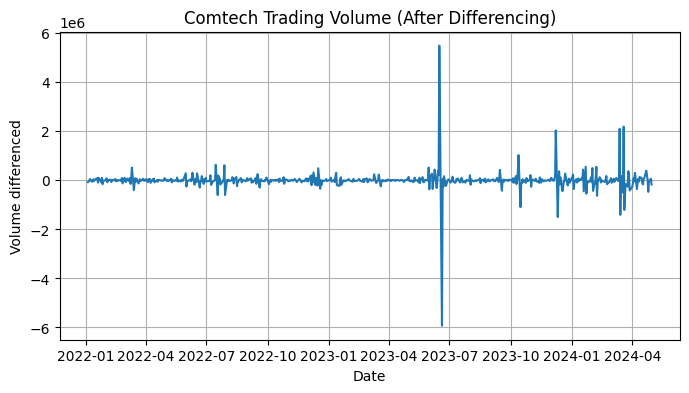

In [58]:
from statsmodels.tsa.stattools import adfuller
adf_cmtl_res=adfuller(cmtl["volume"])
p_value=adf_cmtl_res[1]
print(f"ADF p-value for cmtl: {p_value}")

adf_diff_cmtl=adfuller(cmtl["volume_diff"].dropna())
p_value_diff=adf_diff_cmtl[1]
print(f"ADF p-value for cmtl differenced: {p_value_diff}")

plt.figure(figsize=(8,4))
plt.plot(cmtl.index,cmtl["volume_diff"])
plt.title("Comtech Trading Volume (After Differencing)", fontsize=12)
plt.xlabel("Date", fontsize=10)
plt.ylabel("Volume differenced", fontsize=10)
plt.grid(True)



/tmp/ipykernel_3500/1930944545.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_pfe_res=adfuller(pfe["volume"])
/tmp/ipykernel_3500/1930944545.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_pfe=adfuller(pfe["volume_diff"].dropna())


ADF p-value for pfe: 2.4992205814491154e-11
ADF p-value for cmtl differenced: 3.489824311270907e-17


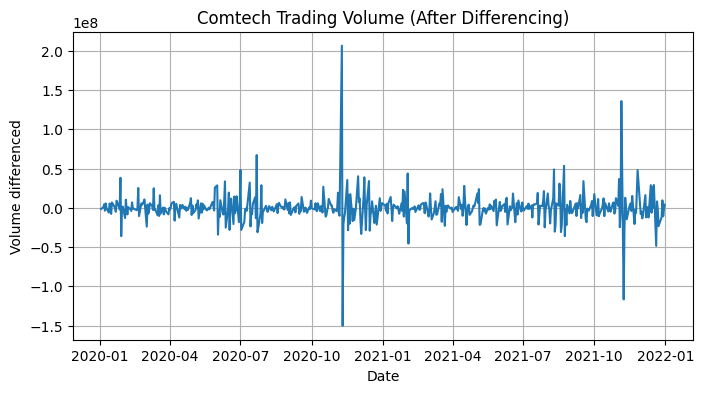

In [59]:

adf_pfe_res=adfuller(pfe["volume"])
p_value=adf_pfe_res[1]
print(f"ADF p-value for pfe: {p_value}")

adf_diff_pfe=adfuller(pfe["volume_diff"].dropna())
p_value_diff=adf_diff_pfe[1]
print(f"ADF p-value for cmtl differenced: {p_value_diff}")

plt.figure(figsize=(8,4))
plt.plot(pfe.index,pfe["volume_diff"])
plt.title("Comtech Trading Volume (After Differencing)", fontsize=12)
plt.xlabel("Date", fontsize=10)
plt.ylabel("Volume differenced", fontsize=10)
plt.grid(True)

Run ARIMA and SARIMA forecasting models

In [60]:
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error

#seperate training and testing data
train=cmtl["volume"].iloc[:-60].reset_index(drop=True)
test=cmtl["volume"].iloc[-60:]

order=(2,1,2)
model=sm.tsa.ARIMA(train, order=order, trend='n').fit()

predictions=model.forecast(steps=len(test))
mae=mean_absolute_error(test, predictions)
mse=mean_squared_error(test, predictions)
rmse=np.sqrt(mse)
print(f"MAE: {mae}")
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")

MAE: 380309.4085022879
MSE: 371086339447.3352
RMSE: 609168.5640669052


ARIMA MAE: 380309.4085022879
ARIMA MSE: 371086339447.3352
ARIMA RMSE: 609168.5640669052


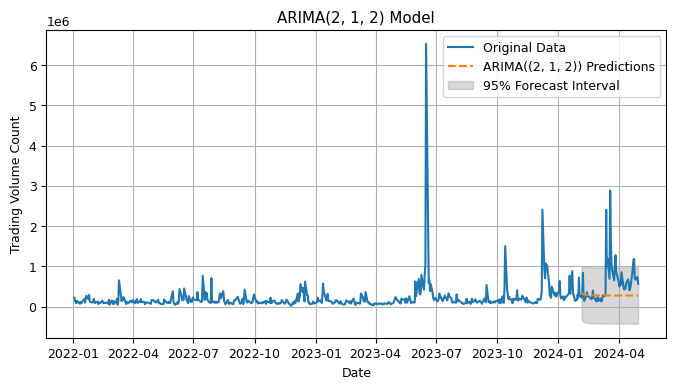

In [61]:
plt.rcParams.update({'font.size': 9})

forecast=model.get_forecast(steps=len(test))
conf_int=forecast.conf_int(alpha=.05)

plt.figure(figsize=(8,4))
plt.plot(cmtl.index,cmtl["volume"], label="Original Data")
plt.plot(test.index, predictions.to_numpy(), label=f'ARIMA({order}) Predictions', linestyle='--')
plt.fill_between(test.index, conf_int.iloc[:, 0].to_numpy(), conf_int.iloc[:,1].to_numpy(), alpha=.3, color='gray', label='95% Forecast Interval')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Trading Volume Count')
plt.title(f'ARIMA{order} Model')
plt.grid(True)

print(f"ARIMA MAE: {mae}")
print(f"ARIMA MSE: {mse}")
print(f"ARIMA RMSE: {rmse}")
plt.show()

In [62]:

def apply_sarima(data, order=(2,1,1), seasonal_order=(1,0,1,5)):
  model= sm.tsa.SARIMAX(
      data,
      order=order,
      seasonal_order=seasonal_order
  )
  results=model.fit(disp=False)
  return results

train=cmtl["volume"].iloc[:-60].reset_index(drop=True)
test=cmtl["volume"].iloc[-60:]

sarima_results=apply_sarima(
    train,
    order=(2,1,1),
    seasonal_order=(1,0,1,5)
)
print(sarima_results.summary())
future_periods=len(test)
forecast=sarima_results.get_forecast(steps=future_periods)

predicted_values=forecast.predicted_mean
confidence_intervals=forecast.conf_int(alpha=.05)

last_date=df.index[-1]
future_dates=test.index

                                     SARIMAX Results                                     
Dep. Variable:                            volume   No. Observations:                  524
Model:             SARIMAX(2, 1, 1)x(1, 0, 1, 5)   Log Likelihood               -7366.029
Date:                           Thu, 22 Oct 2026   AIC                          14744.057
Time:                                   18:28:50   BIC                          14769.615
Sample:                                        0   HQIC                         14754.066
                                           - 524                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2192      0.036      6.048      0.000       0.148       0.290
ar.L2          0.1557      0.041      3.755

In [63]:
mae_sarima=mean_absolute_error(test, predicted_values)
mse_sarima=mean_squared_error(test, predicted_values)
rmse_sarima=np.sqrt(mse_sarima)


print(f"SARIMA MAE: {mae_sarima}")
print(f"SARIMA MSE: {mse_sarima}")
print(f"SARIMA RMSE: {rmse_sarima}")

SARIMA MAE: 375424.32430524286
SARIMA MSE: 361248861851.8817
SARIMA RMSE: 601039.817193405


SARIMA MAE: 375424.32430524286
SARIMA MSE: 361248861851.8817
SARIMA RMSE: 601039.817193405


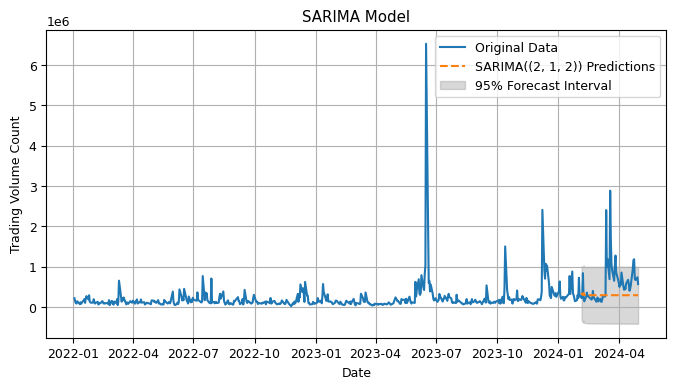

In [64]:
plt.figure(figsize=(8,4))
plt.plot(cmtl.index,cmtl["volume"], label="Original Data")
plt.plot(future_dates, predicted_values.to_numpy(), label=f'SARIMA({order}) Predictions', linestyle='--')
plt.fill_between(future_dates, confidence_intervals.iloc[:, 0].to_numpy(), confidence_intervals.iloc[:,1].to_numpy(), alpha=.3, color='gray', label="95% Forecast Interval")
plt.legend()
plt.xlabel('Date')
plt.ylabel('Trading Volume Count')
plt.title(f'SARIMA Model')
plt.grid(True)

print(f"SARIMA MAE: {mae_sarima}")
print(f"SARIMA MSE: {mse_sarima}")
print(f"SARIMA RMSE: {rmse_sarima}")
plt.show()

Sarima performed better than Arima

In [65]:
baseline=np.repeat(train.iloc[-20:].mean(), len(test))
baseline_mae=mean_absolute_error(test,baseline)
baseline_rmse=np.sqrt(mean_squared_error(test,baseline))
#check whether trading volume would remain equal to the average of the previous 20 trading days
print(f"Baseline MAE: {baseline_mae}")
print(f"Baseline RMSE: {baseline_rmse}")

Baseline MAE: 364393.5
Baseline RMSE: 582905.815441054


In [66]:
#chat code
print("Test observations:", len(test))
print("ARIMA predictions:", len(predictions))
print("SARIMA predictions:", len(predicted_values))

comparison = pd.DataFrame({
    "Actual Volume": test.to_numpy(),
    "ARIMA Prediction": predictions.to_numpy(),
    "SARIMA Prediction": predicted_values.to_numpy()
}, index=test.index)

print(comparison)

Test observations: 60
ARIMA predictions: 60
SARIMA predictions: 60
            Actual Volume  ARIMA Prediction  SARIMA Prediction
Date                                                          
2024-02-05         224000     333204.571102      355347.765930
2024-02-06         288600     322264.483738      314527.714105
2024-02-07         841900     313590.341360      303551.922420
2024-02-08         215400     306652.964912      345164.027837
2024-02-09         143700     301104.735027      299501.834499
2024-02-12         269800     296667.487489      303100.726892
2024-02-13         360700     293118.758233      298164.070485
2024-02-14         271200     290280.629592      296551.290300
2024-02-15         274500     288010.810282      300606.695377
2024-02-16         250300     286195.501553      295789.335969
2024-02-20         187000     284743.691814      296097.541089
2024-02-21         221700     283582.593711      295557.294726
2024-02-22         401100     282653.994896      29

In [67]:
forecast_errors=pd.DataFrame({
    "actual_volume": test.to_numpy(),
    "predicted_volume": predicted_values.to_numpy()
}, index=test.index)

forecast_errors["error"]=(forecast_errors["actual_volume"]-forecast_errors["predicted_volume"])
forecast_errors["volume_ratio"]=(forecast_errors["actual_volume"]/forecast_errors["predicted_volume"])
print(forecast_errors)

            actual_volume  predicted_volume         error  volume_ratio
Date                                                                   
2024-02-05         224000     355347.765930 -1.313478e+05      0.630368
2024-02-06         288600     314527.714105 -2.592771e+04      0.917566
2024-02-07         841900     303551.922420  5.383481e+05      2.773496
2024-02-08         215400     345164.027837 -1.297640e+05      0.624051
2024-02-09         143700     299501.834499 -1.558018e+05      0.479797
2024-02-12         269800     303100.726892 -3.330073e+04      0.890133
2024-02-13         360700     298164.070485  6.253593e+04      1.209737
2024-02-14         271200     296551.290300 -2.535129e+04      0.914513
2024-02-15         274500     300606.695377 -2.610670e+04      0.913153
2024-02-16         250300     295789.335969 -4.548934e+04      0.846210
2024-02-20         187000     296097.541089 -1.090975e+05      0.631549
2024-02-21         221700     295557.294726 -7.385729e+04      0

In [68]:
volume=cmtl["volume"]
train_event=volume.loc[: "2024-03-11"].reset_index(drop=True)
event_dates=volume.loc["2024-03-12":"2024-03-13"]
event_model=sm.tsa.ARIMA(
    train_event,
    order=(2,1,2),
    trend='n'
).fit()

event_forecast=event_model.forecast(
    steps=len(event_dates)
)


event_comparison=pd.DataFrame({
    "actual_volume": event_dates.to_numpy(),
    "predicted_volume": event_forecast.to_numpy()
}, index=event_dates.index)

event_comparison["error"]=(event_comparison["actual_volume"]-event_comparison["predicted_volume"])


print(event_comparison)

            actual_volume  predicted_volume         error
Date                                                     
2024-03-12         302900     247348.176886  5.555182e+04
2024-03-13        2404700     250739.195649  2.153961e+06


In [69]:
event_forecast_result=event_model.get_forecast(
    steps=len(event_dates)
)
event_forecast=event_forecast_result.predicted_mean

In [70]:
#seperate training and testing data
train=pfe["volume"].iloc[:-60].reset_index(drop=True)
test=pfe["volume"].iloc[-60:]

order=(2,1,2)
model=sm.tsa.ARIMA(train, order=order, trend='n').fit()

predictions=model.forecast(steps=len(test))
mae=mean_absolute_error(test, predictions)
mse=mean_squared_error(test, predictions)
rmse=np.sqrt(mse)
print(f"MAE: {mae}")
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")

MAE: 17816543.00509375
MSE: 847583691955884.5
RMSE: 29113290.641146775


ARIMA MAE: 17816543.00509375
ARIMA MSE: 847583691955884.5
ARIMA RMSE: 29113290.641146775


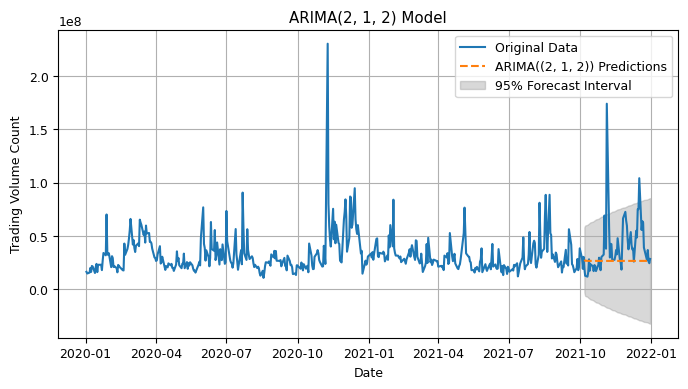

In [71]:
plt.rcParams.update({'font.size': 9})

forecast=model.get_forecast(steps=len(test))
conf_int=forecast.conf_int(alpha=.05)

plt.figure(figsize=(8,4))
plt.plot(pfe.index,pfe["volume"], label="Original Data")
plt.plot(test.index, predictions.to_numpy(), label=f'ARIMA({order}) Predictions', linestyle='--')
plt.fill_between(test.index, conf_int.iloc[:, 0].to_numpy(), conf_int.iloc[:,1].to_numpy(), alpha=.3, color='gray', label='95% Forecast Interval')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Trading Volume Count')
plt.title(f'ARIMA{order} Model')
plt.grid(True)

print(f"ARIMA MAE: {mae}")
print(f"ARIMA MSE: {mse}")
print(f"ARIMA RMSE: {rmse}")
plt.show()

In [72]:

train=pfe["volume"].iloc[:-60].reset_index(drop=True)
test=pfe["volume"].iloc[-60:]

sarima_results=apply_sarima(
    train,
    order=(2,1,1),
    seasonal_order=(1,0,1,5)
)
print(sarima_results.summary())
future_periods=len(test)
forecast=sarima_results.get_forecast(steps=future_periods)

predicted_values=forecast.predicted_mean
confidence_intervals=forecast.conf_int(alpha=.05)

last_date=df.index[-1]
future_dates=test.index

                                     SARIMAX Results                                     
Dep. Variable:                            volume   No. Observations:                  445
Model:             SARIMAX(2, 1, 1)x(1, 0, 1, 5)   Log Likelihood               -7973.874
Date:                           Thu, 22 Oct 2026   AIC                          15959.749
Time:                                   18:29:28   BIC                          15984.323
Sample:                                        0   HQIC                         15969.440
                                           - 445                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2771      0.056      4.942      0.000       0.167       0.387
ar.L2          0.0425      0.063      0.670

SARIMA MAE: 375424.32430524286
SARIMA MSE: 361248861851.8817
SARIMA RMSE: 601039.817193405


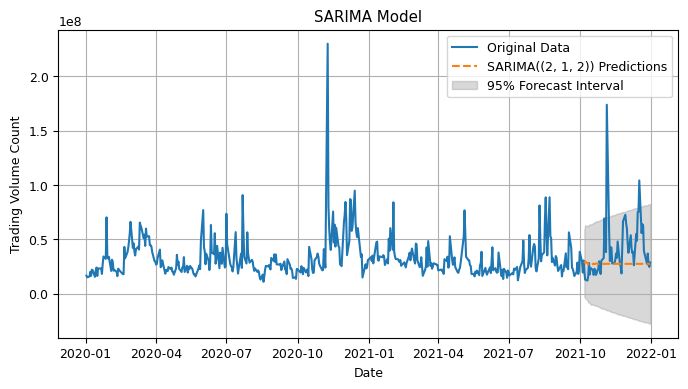

In [73]:
plt.figure(figsize=(8,4))
plt.plot(pfe.index,pfe["volume"], label="Original Data")
plt.plot(future_dates, predicted_values.to_numpy(), label=f'SARIMA({order}) Predictions', linestyle='--')
plt.fill_between(future_dates, confidence_intervals.iloc[:, 0].to_numpy(), confidence_intervals.iloc[:,1].to_numpy(), alpha=.3, color='gray', label="95% Forecast Interval")
plt.legend()
plt.xlabel('Date')
plt.ylabel('Trading Volume Count')
plt.title(f'SARIMA Model')
plt.grid(True)

print(f"SARIMA MAE: {mae_sarima}")
print(f"SARIMA MSE: {mse_sarima}")
print(f"SARIMA RMSE: {rmse_sarima}")
plt.show()

In [74]:
baseline=np.repeat(train.iloc[-20:].mean(), len(test))
baseline_mae=mean_absolute_error(test,baseline)
baseline_rmse=np.sqrt(mean_squared_error(test,baseline))
#check whether trading volume would remain equal to the average of the previous 20 trading days
print(f"Baseline MAE: {baseline_mae}")
print(f"Baseline RMSE: {baseline_rmse}")

Baseline MAE: 17696934.666666668
Baseline RMSE: 28978407.165077813


In [75]:
forecast_errors=pd.DataFrame({
    "actual_volume": test.to_numpy(),
    "predicted_volume": predicted_values.to_numpy()
}, index=test.index)

forecast_errors["error"]=(forecast_errors["actual_volume"]-forecast_errors["predicted_volume"])
forecast_errors["volume_ratio"]=(forecast_errors["actual_volume"]/forecast_errors["predicted_volume"])
print(forecast_errors)

            actual_volume  predicted_volume         error  volume_ratio
Date                                                                   
2021-10-07       19778300      2.780712e+07 -8.028816e+06      0.711268
2021-10-08       12778600      2.946376e+07 -1.668516e+07      0.433706
2021-10-11       11984200      2.798844e+07 -1.600424e+07      0.428184
2021-10-12       16222300      2.682352e+07 -1.060122e+07      0.604779
2021-10-13       28205700      2.779541e+07  4.102946e+05      1.014761
2021-10-14       17590300      2.750045e+07 -9.910154e+06      0.639637
2021-10-15       23550300      2.664289e+07 -3.092590e+06      0.883924
2021-10-18       21733000      2.716566e+07 -5.432662e+06      0.800017
2021-10-19       17159800      2.762498e+07 -1.046518e+07      0.621170
2021-10-20       22788300      2.719817e+07 -4.409873e+06      0.837861
2021-10-21       22142300      2.731797e+07 -5.175670e+06      0.810540
2021-10-22       17183000      2.767995e+07 -1.049695e+07      0

In [76]:
volume=pfe["volume"]
train_event=volume.loc[: "2021-11-03"].reset_index(drop=True)
event_dates=volume.loc["2021-11-04":"2021-11-05"]
event_model=sm.tsa.ARIMA(
    train_event,
    order=(2,1,2),
    trend='n'
).fit()

event_forecast=event_model.forecast(
    steps=len(event_dates)
)


event_comparison=pd.DataFrame({
    "actual_volume": event_dates.to_numpy(),
    "predicted_volume": event_forecast.to_numpy()
}, index=event_dates.index)

event_comparison["error"]=(event_comparison["actual_volume"]-event_comparison["predicted_volume"])


print(event_comparison)

            actual_volume  predicted_volume         error
Date                                                     
2021-11-04       38172500      3.627343e+07  1.899068e+06
2021-11-05      173959100      3.527920e+07  1.386799e+08


In [77]:
event_forecast_result=event_model.get_forecast(
    steps=len(event_dates)
)
event_forecast=event_forecast_result.predicted_mean

In [78]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest

def compute_prediction(X,model_name):
  print(f"Computing predictions with {model_name}")
  if model_name=="LOF":
    clf=LocalOutlierFactor(n_neighbors=20,contamination="auto")
    clf.fit(X)
    y_pred=clf.negative_outlier_factor_
  if model_name=="Iforest":
    clf=IsolationForest(random_state=42, contamination="auto")
    y_pred=clf.fit(X).decision_function(X)
  return y_pred

In [79]:
features=["volume_ratio", "daily_return"]
X_cmtl=cmtl[features].dropna()
X_pfe=pfe[features].dropna()

In [80]:
cmtl_lof=compute_prediction(X_cmtl, "LOF")
cmtl_iforest=compute_prediction(X_cmtl, "Iforest")

pfe_lof=compute_prediction(X_pfe,"LOF")
pfe_iforest=compute_prediction(X_pfe,"Iforest")

Computing predictions with LOF
Computing predictions with Iforest
Computing predictions with LOF
Computing predictions with Iforest


In [81]:
X_cmtl=X_cmtl.copy()
X_pfe=X_pfe.copy()

X_cmtl["lof"]=cmtl_lof
X_cmtl["iforest"]=cmtl_iforest
X_pfe["lof"]=pfe_lof
X_pfe["iforest"]=pfe_iforest

In [82]:
print(X_cmtl.loc["2024-03-12":"2024-03-13"])
print(X_pfe.loc["2021-11-04":"2021-11-05"])

Price       volume_ratio  daily_return       lof   iforest
Date                                                      
2024-03-12      1.341809      0.523564 -1.105130  0.106814
2024-03-13     10.574991    -27.256946 -4.159974 -0.309697
Price       volume_ratio  daily_return       lof   iforest
Date                                                      
2021-11-04      1.524271     -2.164215 -1.112646  0.044941
2021-11-05      6.700313     10.855193 -4.472613 -0.321840


In [83]:
def rolling_zscore(x: pd.Series, window: int,min_periods: int=20) -> pd.Series:
  mu=x.rolling(window=window, min_periods=min_periods).mean().shift(1)
  sigma=x.rolling(window=window, min_periods=min_periods).std(ddof=0).shift(1)
  sigma=sigma.replace(0,np.nan)
  zscore=(x-mu)/sigma
  return zscore


In [84]:
window=20
z_cmtl=rolling_zscore(cmtl["volume"], window)
z_thr=3.0
pred_roll_z_cmtl=(z_cmtl>z_thr).fillna(False)
print("Comtech rolling Z-score flags: ", int(pred_roll_z_cmtl.sum()))

Comtech rolling Z-score flags:  28


In [85]:
window=20
z_pfe=rolling_zscore(pfe["volume"], window)
z_thr=3.0
pred_roll_z_pfe=(z_pfe>z_thr).fillna(False)
print("Pfizer rolling Z-score flags: ", int(pred_roll_z_pfe.sum()))

Comtech rolling Z-score flags:  19


In [91]:
cmtl["volume_zscore"]=z_cmtl
pfe["volume_zscore"]=z_pfe

cmtl["zscore_anomaly"]=pred_roll_z_cmtl
pfe["zscore_anomaly"]=pred_roll_z_pfe

In [92]:
cmtl.loc["2024-03-12":"2024-03-13", ["volume", "volume_zscore", "zscore_anomaly"]]


Price,volume,volume_zscore,zscore_anomaly
Date,,,
2024-03-12,302900,1.062135,False
2024-03-13,2404700,29.424807,True


In [93]:
pfe.loc["2021-11-04":"2021-11-05", ["volume", "volume_zscore", "zscore_anomaly"]]

Price,volume,volume_zscore,zscore_anomaly
Date,,,
2021-11-04,38172500,1.046430,False
2021-11-05,173959100,11.563258,True


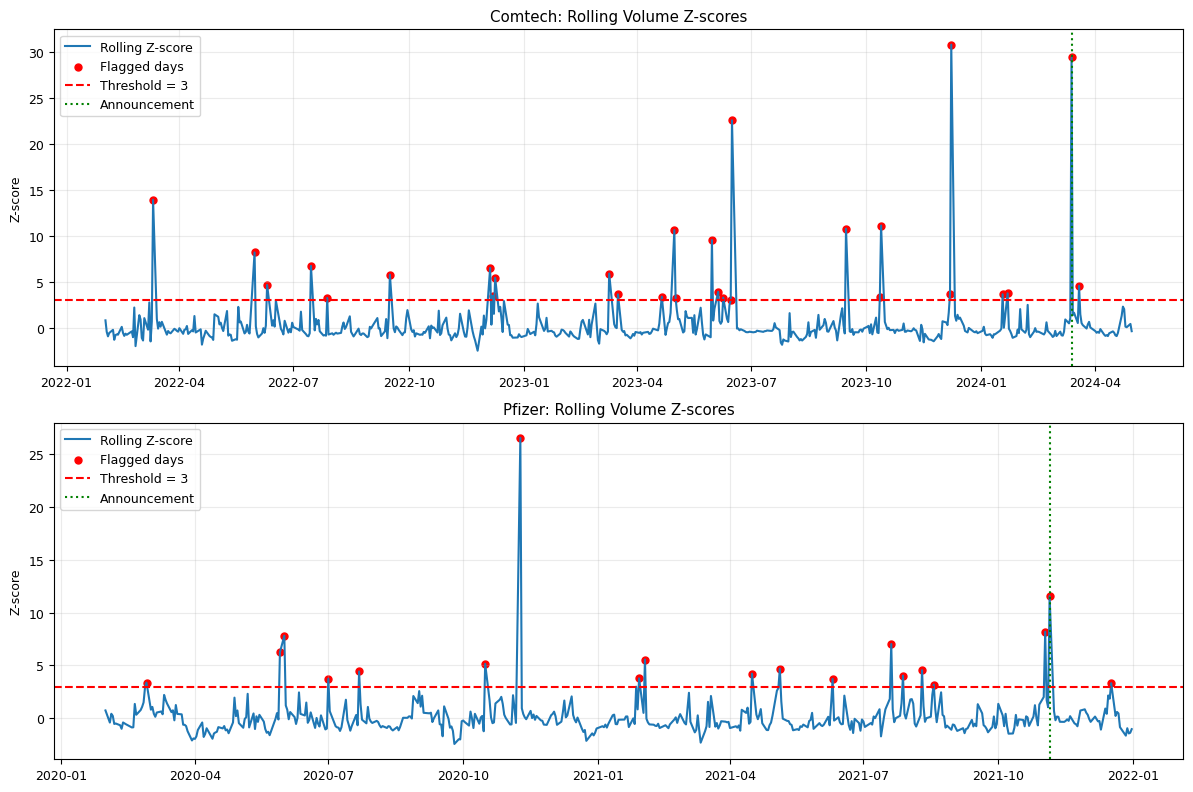

In [95]:
fig, axes = plt.subplots(2,1,figsize=(12,8))
datasets=[(cmtl, "Comtech", "2024-03-13"), (pfe, "Pfizer", "2021-11-05")]

for ax, (df,name,announcement) in zip(axes,datasets):
  ax.plot(df.index, df["volume_zscore"], label="Rolling Z-score")

  flagged=df[df["zscore_anomaly"]]
  ax.scatter(flagged.index, flagged["volume_zscore"], color="red", s=25, label="Flagged days")

  ax.axhline(3, color="red", linestyle="--", label="Threshold = 3")

  ax.axvline(pd.Timestamp(announcement), color="green", linestyle=":", label="Announcement")

  ax.set_title(f"{name}: Rolling Volume Z-scores")
  ax.set_ylabel("Z-score")
  ax.legend()
  ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [96]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

def lof_flags(X):
  features= X[["volume_ratio", "daily_return"]].dropna()
  scaled=StandardScaler().fit_transform(features)
  model=LocalOutlierFactor(n_neighbors=20, contamination="auto")
  return pd.Series(model.fit_predict(scaled) == -1, index=features.index)

X_cmtl["lof_anomaly"]=lof_flags(X_cmtl)
X_pfe["lof_anomaly"]=lof_flags(X_pfe)

In [97]:
X_cmtl["iforest_anomaly"]=X_cmtl["iforest"]<0
X_pfe["iforest_anomaly"]=X_pfe["iforest"]<0


In [98]:
def event_comparison(df,X,dates,company):
  result=df.loc[dates,["volume", "volume_zscore", "zscore_anomaly"]].copy()

  result["lof_anomaly"]=X["lof_anomaly"]
  result["iforest_anomaly"]=X["iforest_anomaly"]
  result["company"] = company

  return result

cmtl_event=event_comparison(cmtl,X_cmtl,["2024-03-12","2024-03-13"],"Comtech")

pfe_event=event_comparison(pfe,X_pfe,["2021-11-04","2021-11-05"],"Pfizer")

comparison=pd.concat([cmtl_event, pfe_event])

display(comparison)

Price,volume,volume_zscore,zscore_anomaly,lof_anomaly,iforest_anomaly,company
Date,,,,,,
2024-03-12,302900,1.062135,False,False,False,Comtech
2024-03-13,2404700,29.424807,True,True,True,Comtech
2021-11-04,38172500,1.046430,False,False,False,Pfizer
2021-11-05,173959100,11.563258,True,True,True,Pfizer


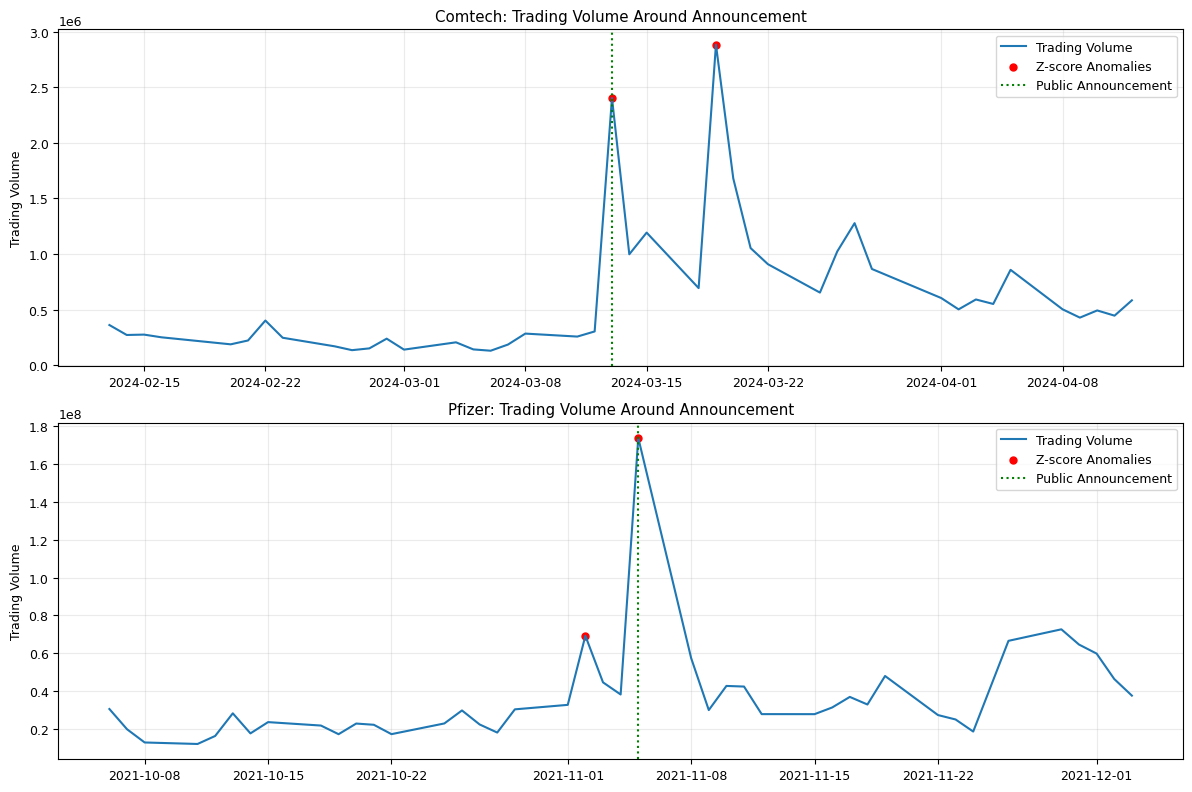

In [99]:
fig, axes =plt.subplots(2,1,figsize=(12,8))

datasets=[
    (cmtl, "Comtech", "2024-03-13", "2024-02-13", "2024-04-12"),
    (pfe, "Pfizer", "2021-11-05", "2021-10-06", "2021-12-03")

]

for ax, (df, name, announcement,start, end) in zip(axes, datasets):
  subset = df.loc[start:end]
  ax.plot(subset.index, subset["volume"], label="Trading Volume")

  flagged=subset[subset["zscore_anomaly"]]
  ax.scatter(flagged.index, flagged["volume"], color="red", s=25, label="Z-score Anomalies")

  ax.axvline(
      pd.Timestamp(announcement), color="green", linestyle=":", label="Public Announcement"

  )

  ax.set_title(f"{name}: Trading Volume Around Announcement")
  ax.set_ylabel("Trading Volume")
  ax.legend()
  ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()